# scVI integration and annotation 

## Setup

In [1]:
import os
import re
import pandas as pd
import numpy as np
import scanpy as sc
from collections import defaultdict

from pathlib import Path
import anndata as ad
import gc
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import seaborn as sns

import scvi

os.environ["RPY2_CFFI_MODE"] = "ABI"



/opt/miniconda3/envs/cap/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
project  = Path(os.environ.get("CAP_PROJECT","~/Downloads/1105_Project_Nowotny")).expanduser()
raw_dir  = Path(os.environ.get("CAP_RAW_DATA","~/Downloads/Project_Nowotny/Helena/raw_counts")).expanduser()
head_dir  = project / "Adata_Saves" / "head"
save_dir  = project / "Adata_Saves"
model_dir = project / "scvi_model"
fig_dir   = project / "Figures"
df_dir    = project / "Dataframe_Saves"

for d in [head_dir, save_dir, model_dir, fig_dir, df_dir]:
    d.mkdir(parents=True, exist_ok=True)

In [3]:

sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N2": "#031A6B", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic Cells": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial Cells": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # allback
    "Unknown": "#808080"#grey
}

In [4]:
# one ordering for every condition-aware figure; labels carry a "+" from here on
condition_order = ["N", "TN", "HER2+", "ER+"]
condition_rank = {c: i for i, c in enumerate(condition_order)}


# Loading Files

In [ ]:
adatas          = []#keeping all AnnData objects in memory
summary_list    = []#per-sample stats
condition_hvgs  = defaultdict(lambda: None)#HVG intersection per condition
skipped         = []

In [6]:
samples = pd.read_csv(project / "metadata" / "samples.csv")
wanted  = samples.loc[samples["include"], "sample_id"].tolist()
print(f"{len(wanted)} samples expected")

adatas = []

for sample_id in wanted:
    path = head_dir / f"{sample_id}.h5ad"
    assert path.exists(), f"missing: {sample_id} - rerun papermill"
    a = sc.read_h5ad(path)
    a.obs["sample"] = sample_id
    adatas.append(a)


assert len(adatas) == len(wanted), f"loaded {len(adatas)}, expected {len(wanted)}"
print(f"{len(adatas)} loaded, {sum(a.n_obs for a in adatas):,} cells")

45 samples expected
45 loaded, 238,187 cells


In [ ]:

# per-sample binomial deviance from 001, kept as a small genes x samples table so that the per-sample objects can be released straight after the concatenation
deviance = pd.DataFrame({s: a.var["deviance"] for s, a in zip(wanted, adatas)})

deviance.shape

(33538, 45)

# Concatenation

In [8]:
adata = ad.concat(adatas, join="inner", label="batch", keys=wanted,
                  index_unique="-", merge="same")

adata.obs["condition"] = adata.obs["sample"].str.split("_").str[1].str.split("-").str[0]
adata.obs["patient"] = adata.obs["sample"].map(dict(zip(samples.sample_id, samples.patient)))


In [9]:
d = adata.layers["counts"].data
assert np.allclose(d, np.round(d)), "counts layer is not integer"


In [ ]:
del adatas
gc.collect()

adata

AnnData object with n_obs × n_vars = 238187 × 33538
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb'
    obsm: 'X_pca'
    layers: 'counts', 'log1p'

# Gene filtering and HVG

In [11]:
sc.pp.filter_genes(adata, min_cells=3)
print("genes after filter:", adata.n_vars)

for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    assert g in adata.var_names, f"{g} was filtered out"

genes after filter: 28552


In [ ]:
# aggregated by the maximum across samples, so a gene deviant in a single subtype is retained
adata.var["binomial_deviance"] = deviance.reindex(adata.var_names).max(axis=1)

assert adata.var["binomial_deviance"].notna().all()

In [13]:
s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","HELLS","RFC2","RPA2","NASP","RAD51AP1",
           "GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2","RAD51",
           "RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2","USP1",
           "CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]


In [14]:


g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80","CKS2",
             "NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","SMC4","CCNB2","CKAP2L",
             "CKAP2","AURKB","BUB1","KIF11","ANP32E","TUBB4B","GTSE1","KIF20B",
             "HJURP","CDCA3","CDC20","TTK","CDC25C","KIF2C","RANGAP1","NCAPD2",
             "DLGAP5","CDCA2","CDCA8","ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN",
             "LBR","CKAP5","CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]


In [15]:

# ranked after removing genes whose variation is technical or cell-cycle driven
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()
exclude |= adata.var_names.isin(s_genes + g2m_genes)
exclude |= adata.var_names.str.match(r"^IG[HKL][VDJC]")


In [ ]:

ranked = adata.var.loc[~exclude, "binomial_deviance"].sort_values(ascending=False)

In [17]:

adata.var["highly_variable"] = adata.var_names.isin(ranked.index[:2000])

assert adata.var["highly_variable"].sum() == 2000

In [18]:
adata.var["highly_variable"].sum()

np.int64(2000)

## Inspection Before Integration

In [19]:
adata_pre = adata[:, adata.var["highly_variable"]].copy()
adata_pre.X = adata_pre.layers["log1p"]
print(f"Shape after HVG subset: {adata_pre.shape}") #cells × intersection genes

sc.pp.scale(adata_pre, max_value=10, zero_center=False)
sc.tl.pca(adata_pre, n_comps=20, zero_center=False)

#batch correction before neighbors
sc.pp.neighbors(adata_pre, use_rep="X_pca", n_pcs=20, n_neighbors=15)
sc.tl.umap(adata_pre)

Shape after HVG subset: (238187, 2000)


In [20]:
qc = pd.concat([pd.read_csv(f) for f in sorted(df_dir.glob("qc_*.csv"))])
qc = qc.sort_values(["condition", "sample"]).reset_index(drop=True)
qc.to_csv(project / "metadata" / "qc_summary.csv", index=False)


In [21]:

print(qc.groupby("condition")[["n_cells_final", "miqc_mt_cutoff", "pct_doublets"]]
        .agg(["count", "sum", "median"]).round(1).to_string())


          n_cells_final                miqc_mt_cutoff               pct_doublets              
                  count    sum  median          count    sum median        count    sum median
condition                                                                                     
ER                   18  96505  5442.0             18  297.9   12.4           18  152.6    8.3
HER2                  6  38352  4815.0              6  127.6   19.1            6   53.1    8.0
N                    13  51208  4062.0             13  194.7   10.7           13   89.9    6.9
TN                    8  52122  4971.5              8  147.7   12.0            8   71.2    8.8


In [23]:
qc


,sample,condition,n_cells_final,n_genes,miqc_mt_cutoff,pct_doublets,pc1_depth_corr,median_counts,median_genes,ror1_egfr_dp,ror1_egfr_dp_doublet_pct,epcam_erbb2_dp,epcam_erbb2_dp_doublet_pct,miqc_converged,mt_filter_path,mt_floor
0,GSM4909295_ER-AH0319,ER,2870,33538,11.4,5.8,-0.701,2148,869,16,0.0,264,5.7,True,miqc,10
1,GSM4909296_ER-MH0001,ER,6279,33538,10.0,10.4,-0.609,1341,533,0,NaN,22,22.7,True,miqc,10
2,GSM4909297_ER-MH0125,ER,6411,33538,10.0,11.0,0.695,954,522,3,0.0,357,19.3,True,miqc,10
3,GSM4909298_ER-PM0360,ER,5486,33538,18.2,8.3,0.712,1210,537,1,0.0,218,9.6,True,miqc,10
4,GSM4909299_ER-MH0114-T3,ER,7595,33538,10.0,10.8,0.520,2765,1115,9,22.2,1304,21.0,True,miqc,10
5,GSM4909300_ER-MH0032,ER,1229,33538,11.1,4.1,0.572,2192,864,1,0.0,97,5.2,True,miqc,10
6,GSM4909301_ER-MH0042,ER,4720,33538,10.0,8.3,0.489,1665,765,0,NaN,99,14.1,True,miqc,10
7,GSM4909302_ER-MH0025,ER,8237,33538,11.1,11.2,-0.576,1725,807,1,0.0,385,23.1,True,miqc,10
8,GSM4909303_ER-MH0151,ER,2601,33538,28.6,5.4,0.728,2220,968,22,4.5,350,4.3,True,miqc,10
9,GSM4909304_ER-MH0163,ER,5935,33538,31.3,8.2,0.716,3964,1432,0,NaN,371,14.6,True,miqc,10


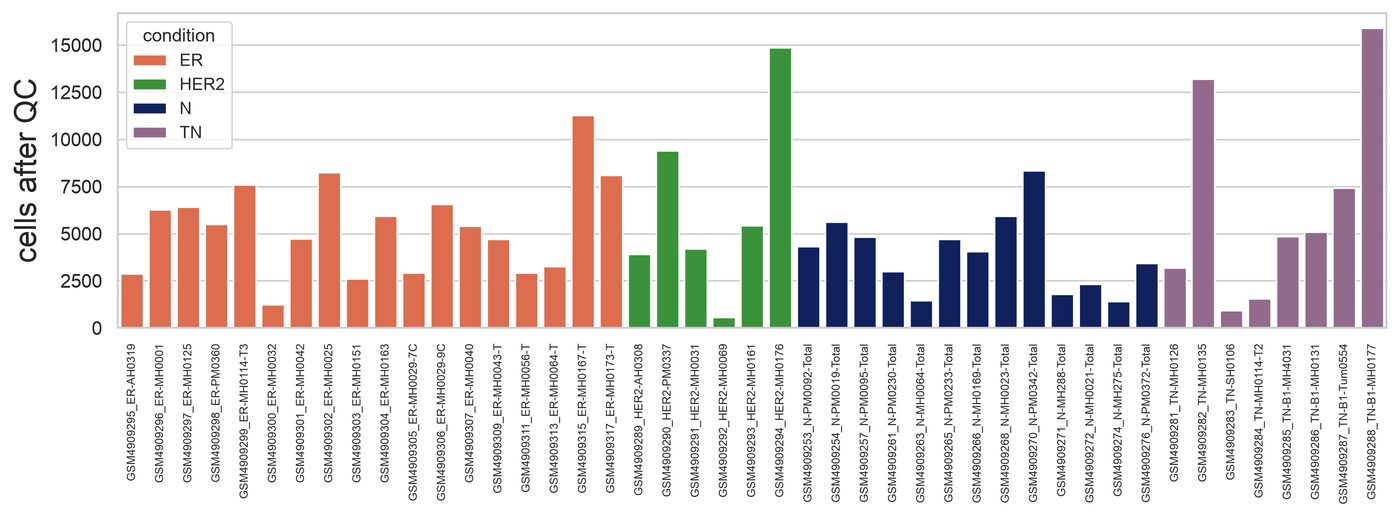

In [24]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(data=qc, x="sample", y="n_cells_final", hue="condition",
            palette=condition_palette, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="cells after QC")
ax.tick_params(axis="x", rotation=90, labelsize=6)
plt.savefig(fig_dir / "cells_per_sample.png", dpi=300, bbox_inches="tight")
plt.show()


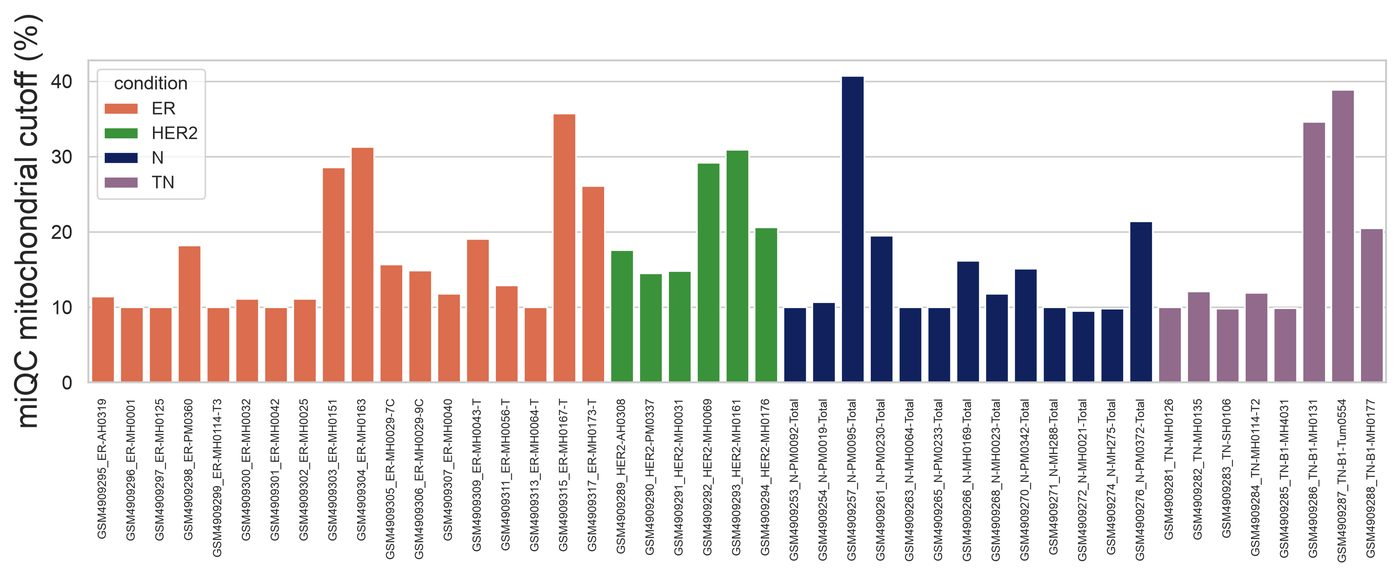

In [25]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(data=qc, x="sample", y="miqc_mt_cutoff", hue="condition",
            palette=condition_palette, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="miQC mitochondrial cutoff (%)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
plt.savefig(fig_dir / "miqc_cutoff_per_sample.png", dpi=300, bbox_inches="tight")
plt.show()


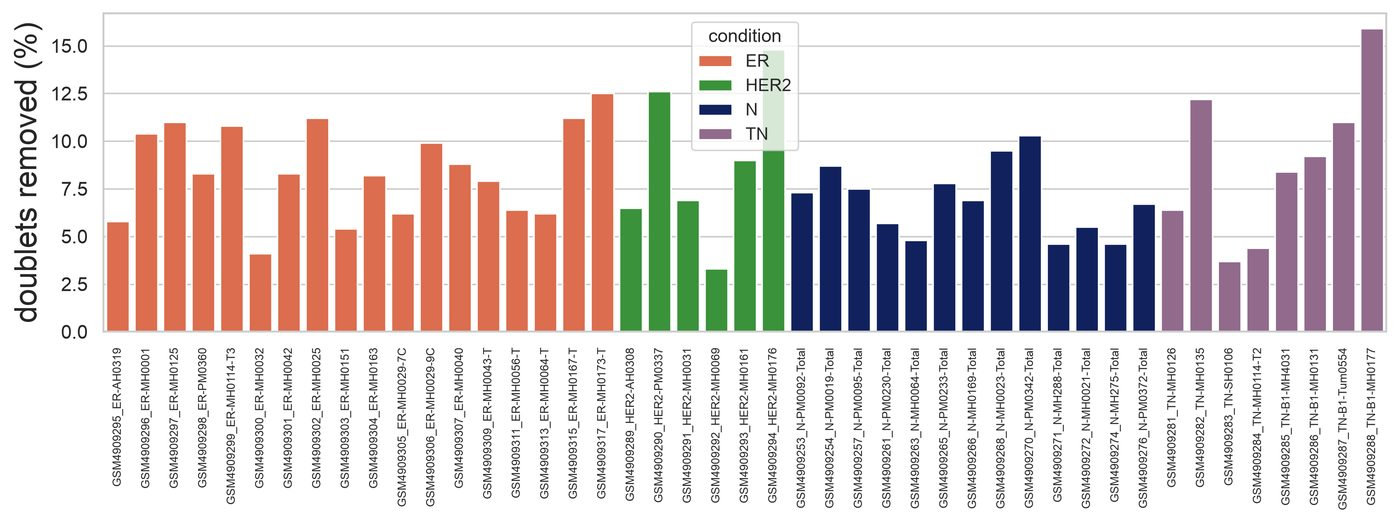

In [26]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(data=qc, x="sample", y="pct_doublets", hue="condition",
            palette=condition_palette, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="doublets removed (%)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
plt.savefig(fig_dir / "doublets_per_sample.png", dpi=300, bbox_inches="tight")
plt.show()


/var/folders/rh/9t2thrd93sj5g64z90ykd_4r0000gn/T/ipykernel_100/1549514570.py:3: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


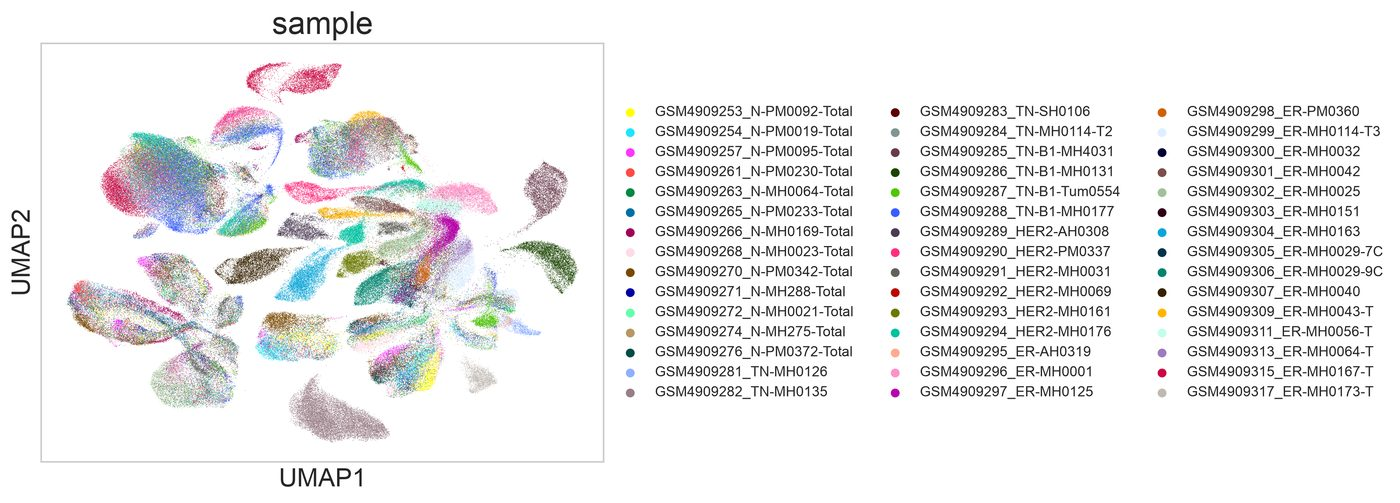

In [27]:
#1d UMAP pre-integration
sc.pl.umap(adata_pre, color="sample", show=False)
plt.tight_layout()
plt.savefig(fig_dir / "2_Before_Concat.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
del adata_pre
gc.collect()

34062

# scVI integration

In [30]:
# immunoglobulin genes are excluded before ranking, so none should be selected
assert not (adata.var_names.str.match(r"^IG[HKL][VDJC]") & adata.var["highly_variable"]).any()

In [31]:
adata_scvi = adata[:, adata.var["highly_variable"]].copy()

In [36]:
scvi.settings.seed = 0
scvi.settings.num_workers = 4

scvi.model.SCVI.setup_anndata(adata_scvi, layer="counts", batch_key="sample")
model = scvi.model.SCVI(adata_scvi, n_latent=30, n_layers=2, gene_likelihood="nb")
model.train(max_epochs=400, accelerator="mps", batch_size=1024,
            early_stopping=True, early_stopping_patience=20,
            early_stopping_min_delta=0.5)

Seed set to 0
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/minico

Epoch 257/400:  64%|██████▍   | 257/400 [29:06<16:11,  6.80s/it, v_num=1, train_loss=1.38e+3]
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 1380.161. Signaling Trainer to stop.


In [37]:
print(f"stopped after {model.history['elbo_train'].shape[0]} epochs")
model.save(str(model_dir), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_atlas_history.csv")

stopped after 257 epochs


In [38]:

adata_scvi.obsm["X_scVI"] = model.get_latent_representation()
assert not np.isnan(adata_scvi.obsm["X_scVI"]).any()


In [39]:
del model
gc.collect()


2942

In [40]:

adata.obsm["X_scVI"] = adata_scvi.obsm["X_scVI"]


In [41]:
del adata_scvi
gc.collect()

0

# Neighbors and UMAP

In [42]:
#Neighbors and UMAP on scVI latent space
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=30, random_state=0)
sc.tl.leiden(adata, key_added="scVI_leiden", resolution=1,
             flavor="igraph", n_iterations=2, directed=False, random_state=0)
sc.tl.umap(adata, random_state=0)

In [43]:
#checking correlation between scVI latent dim 1 and total counts
r = np.corrcoef(adata.obsm["X_scVI"][:, 0], adata.obs["total_counts"])[0, 1]
print(f"scVI latent dim 1 vs total counts: r = {r:+.2f}")   # want near zero

scVI latent dim 1 vs total counts: r = +0.23


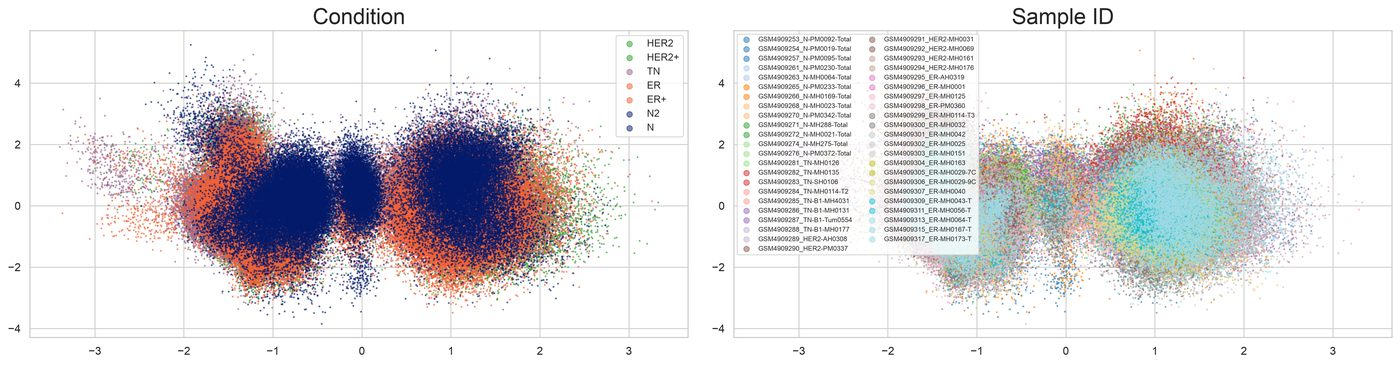

In [44]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit_transform(adata.obsm["X_scVI"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

#0a Color by condition
conditions = adata.obs["condition"].astype("category")
for cond, color in condition_palette.items():
    mask = conditions == cond
    axes[0].scatter(pca[mask, 0], pca[mask, 1], s=1, label=cond, color=color, alpha=0.5)
axes[0].set_title("Condition")
axes[0].legend(markerscale=5)

#0b Color by patient
patients = adata.obs["sample"].astype("category")
colors = plt.cm.tab20(np.linspace(0, 1, len(patients.cat.categories)))
for i, pat in enumerate(patients.cat.categories):
    mask = patients == pat
    axes[1].scatter(pca[mask, 0], pca[mask, 1], s=1, label=pat, color=colors[i], alpha=0.5)
axes[1].set_title("Sample ID")
axes[1].legend(markerscale=5, fontsize=6, ncol=2)
del pca
gc.collect()
plt.tight_layout()
plt.show()

plt.savefig(fig_dir / "scvi_latent_pca.png", dpi=300, bbox_inches="tight")


In [ ]:
# Batch mixing: what fraction of each cell's neighbours come from the same sample? 
conn  = adata.obsp["connectivities"].tocsr()
codes = adata.obs["sample"].astype("category").cat.codes.to_numpy()

same       = (codes[conn.indices] == np.repeat(codes, np.diff(conn.indptr)))
n_nb       = np.maximum(np.diff(conn.indptr), 1)
frac_same  = np.add.reduceat(same, conn.indptr[:-1]) / n_nb

p        = adata.obs["sample"].value_counts(normalize=True).to_numpy()
expected = (p ** 2).sum()

print(f"neighbours from the same sample : {frac_same.mean():.3f}")
print(f"expected if perfectly mixed     : {expected:.3f}")
print(f"ratio                           : {frac_same.mean() / expected:.1f}x")


neighbours from the same sample : 0.412
expected if perfectly mixed     : 0.032
ratio                           : 13.1x


In [47]:
adata

AnnData object with n_obs × n_vars = 238187 × 28552
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable'
    uns: 'neighbors', 'scVI_leiden', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap'
    layers: 'counts', 'log1p'
    obsp: 'distances', 'connectivities'

In [48]:
adata.write_h5ad(save_dir / "project_integrated.h5ad", compression="gzip")

[<Axes: title={'center': 'sample'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'condition'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'patient'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'scVI_leiden'}, xlabel='UMAP1', ylabel='UMAP2'>]

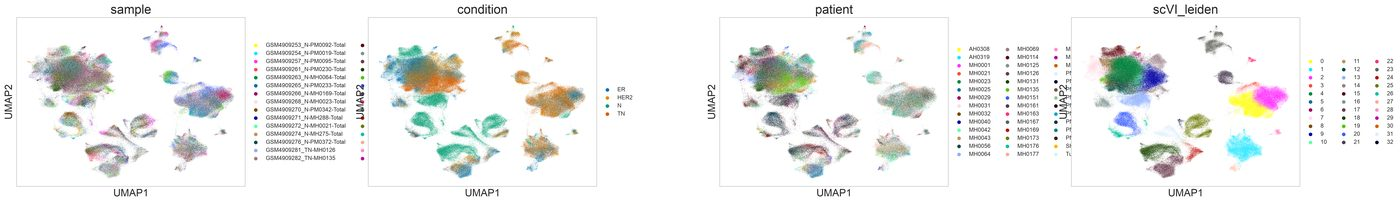

In [49]:
sc.pl.umap(adata, color=["sample", "condition", "patient", "scVI_leiden"], wspace=0.4, show=False)

plt.savefig(fig_dir / "umap_sample_condition_patient_leiden.png", dpi=300, bbox_inches="tight")
plt.show()


# Celltype Annotation

In [50]:
adata.obs["condition"] = adata.obs["condition"].str.replace("^ER$", "ER+", regex=True)
adata.obs["condition"] = adata.obs["condition"].str.replace("^HER2$", "HER2+", regex=True)

# condition_order is defined once at the top of the notebook and reused here
adata.obs["condition"] = pd.Categorical(
    adata.obs["condition"], categories=condition_order, ordered=True
)

In [51]:
unexpected = set(adata.obs["condition"].unique()) - set(condition_order)
print(unexpected)#should be empty set()

set()


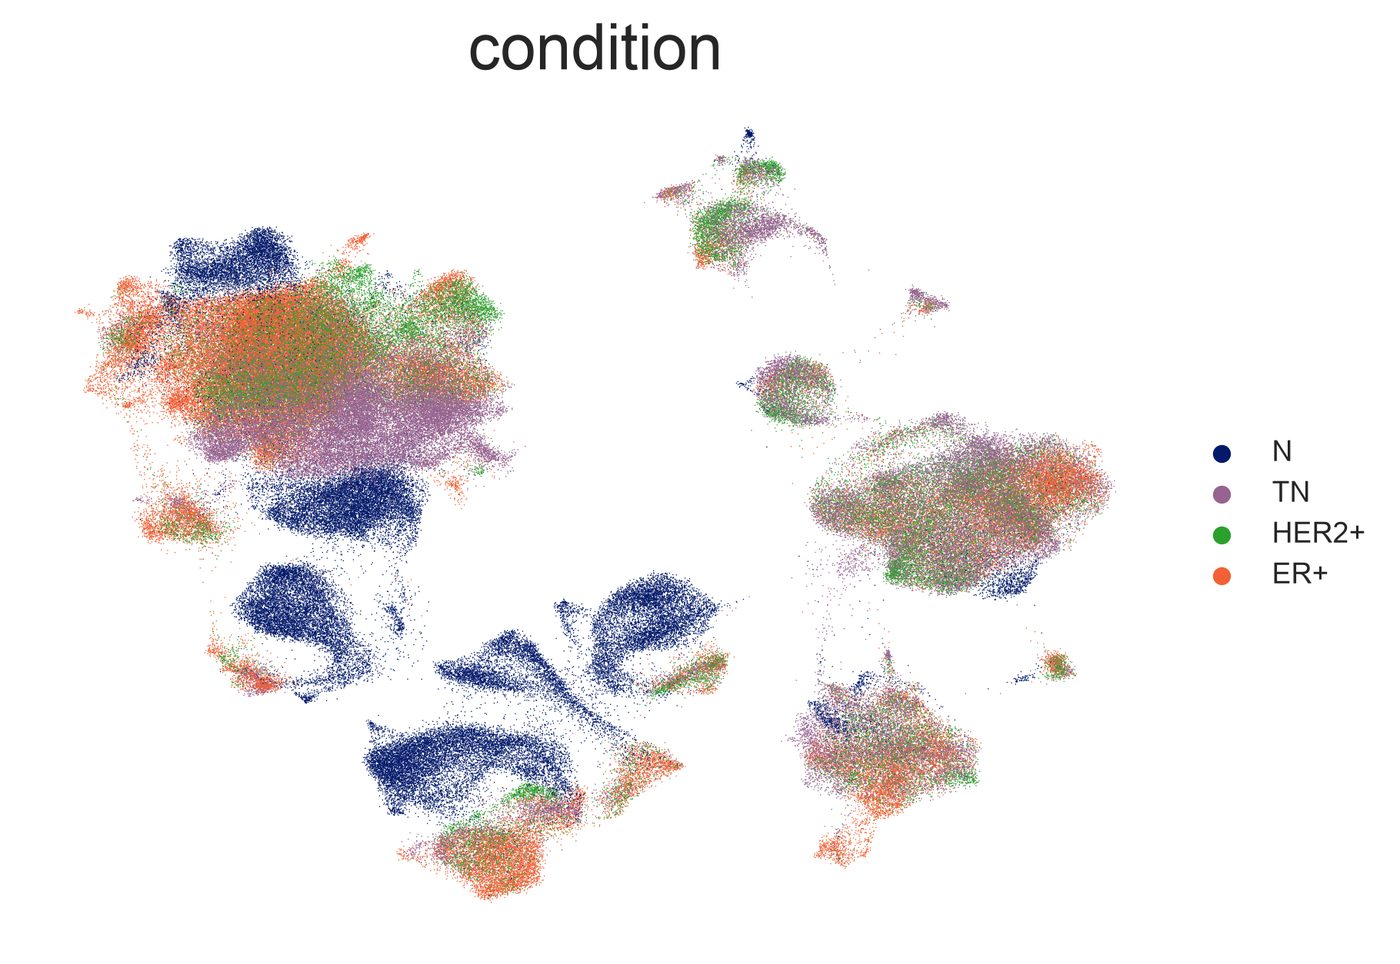

In [52]:
# UMAP coloured by condition
sc.pl.umap(adata, color=["condition"], palette=condition_palette, frameon=False, show=False)
savefig = plt.savefig(fig_dir /  "2_Cond_ID.png", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
adata.obs["sample_short"] = (
    adata.obs["sample"]
    .astype(str)
    .str.strip()
    .str.replace(".h5ad", "", regex=False)
    .str.split("_", n=1).str[-1]
    .str.replace(r"^(TN|ER|HER2|N)-", "", regex=True)
    .astype("category")
)
print("done")
from matplotlib.lines import Line2D


done


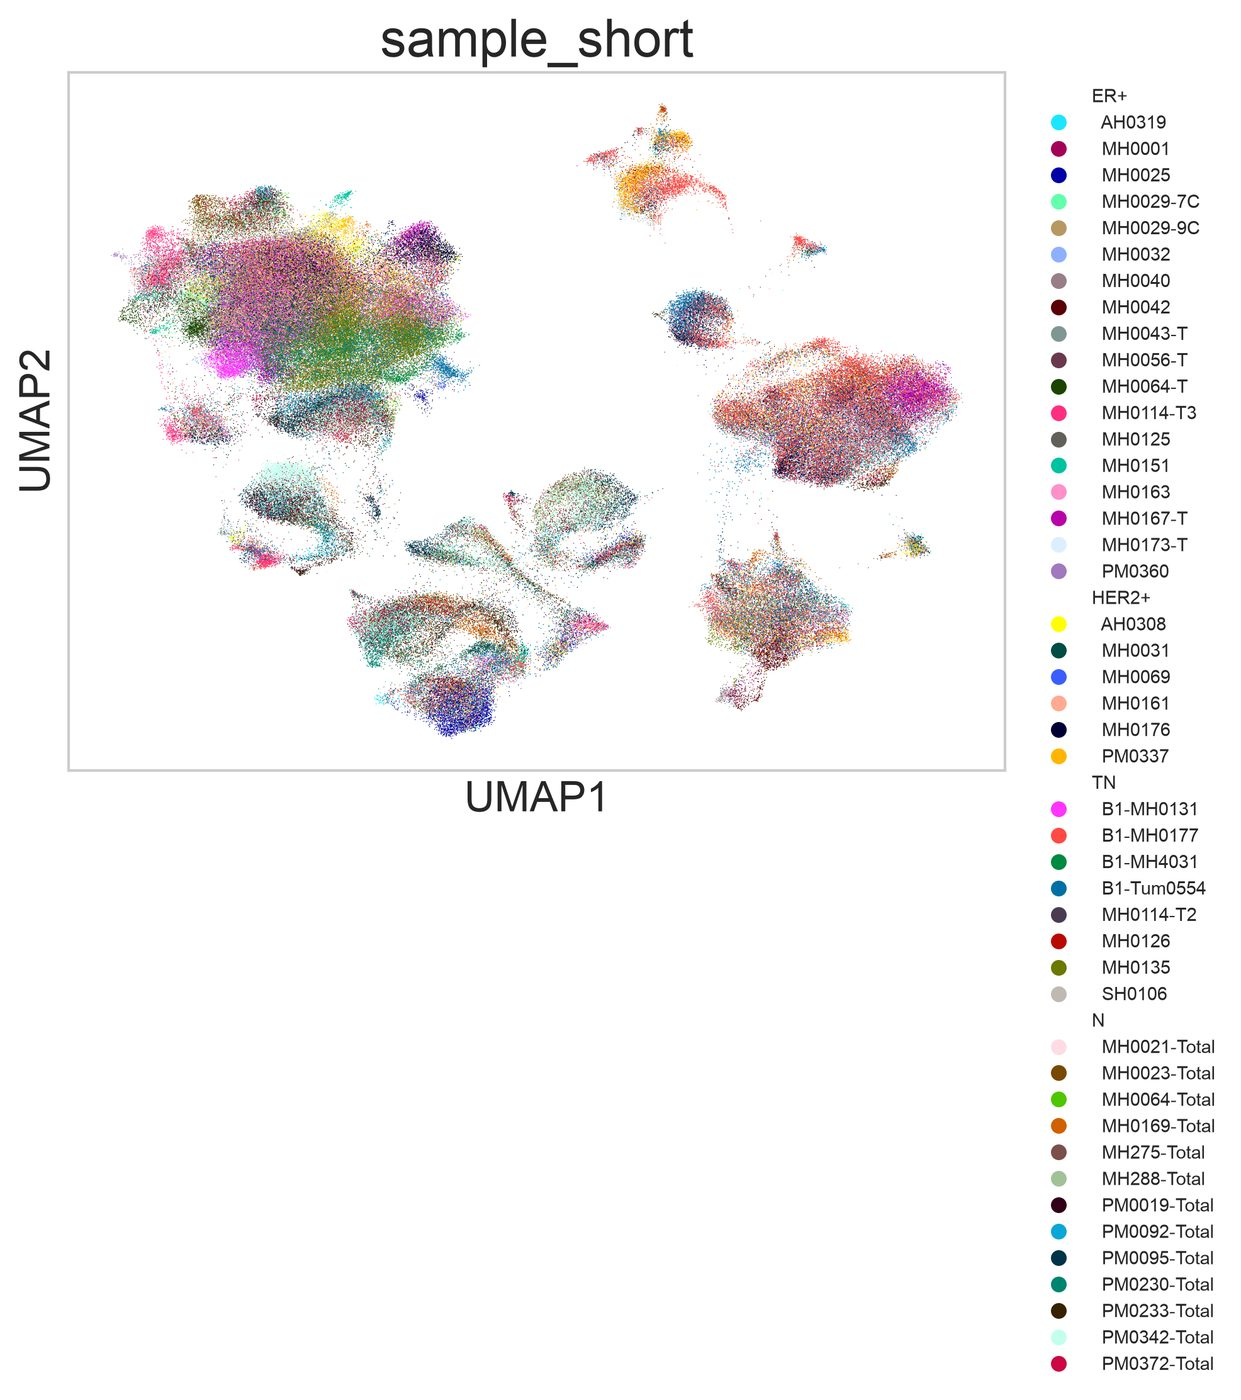

In [54]:

# 3 UMAP coloured by sample with short sample names plotting UMAP without default legend
sc.pl.umap( adata, color="sample_short", legend_loc=None,show=False)
ax = plt.gca()

#extract colours assigned by Scanpy
samples = adata.obs["sample_short"].cat.categories
colors  = adata.uns["sample_short_colors"]

sample_to_color = dict(zip(samples, colors))

#building grouped legend
handles = []

for condition in ["ER+", "HER2+", "TN", "N"]:

    #header (invisible marker)
    handles.append(Line2D([], [], linestyle="none", label=f"{condition}",color="black"))

    #samples belonging to this condition
    cond_samples = (adata.obs.loc[adata.obs["condition"] == condition, "sample_short"].unique())

    for sample in sorted(cond_samples):

        handles.append(Line2D([], [], marker="o", linestyle="none", markersize=6,markerfacecolor=sample_to_color[sample], markeredgecolor="none", label=f"  {sample}"))

#drawing legend
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(fig_dir /  "3_All_Sample.png", dpi=300, bbox_inches="tight")
plt.show()

# DEGs

In [55]:
adata.layers["lognorm"] = adata.layers["log1p"]

In [56]:
sc.tl.rank_genes_groups(adata, groupby="scVI_leiden", layer="lognorm", method="wilcoxon")

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:463: PerformanceWarning: DataFrame is high

In [57]:
degs = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(30)
degs.to_csv(df_dir / "cluster_degs.csv", index=False)
degs.head(15)

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
0,B2M,FTL,CCL5,HMGB1,KRT19,MIEN1,ERBB2,MGP,MALAT1,STMN1,...,SSR4,IGFBP7,IGFBP7,TAGLN,ACP5,TPSAB1,COX6C,MUCL1,MT1A,TFPI
1,BTG1,TYROBP,B2M,STMN1,COX6C,PSMB3,ABRACL,XBP1,TRPS1,PCLAF,...,MZB1,CALD1,TM4SF1,KRT17,CST3,TPSB2,RAMP1,MT-CO3,MT2A,AKAP12
2,TMSB4X,CD74,NKG7,ACTB,XBP1,ERBB2,HEBP2,AZGP1,ANKRD30A,H2AFZ,...,IGKC,SPARCL1,PCAT19,KRT14,CTSK,CPA3,FABP3,TSPAN1,C11orf96,SQSTM1
3,HLA-A,HLA-DRA,TMSB4X,HMGB2,KRT18,RPL23,SPINK8,STC2,KRT19,CKS1B,...,IGHG1,MYL9,ADAMTS9,MYLK,SPP1,SRGN,MGP,CRISP3,AKAP12,NEAT1
4,RPS27,FCER1G,CD52,HMGN2,SMIM22,RPL19,MPHOSPH6,ANKRD30A,NEAT1,HMGN2,...,IGHG3,TAGLN,CD93,MT1X,RGS10,RGS1,PTP4A2,MT-ND1,EIF1,HMOX1
5,CD3D,HLA-DRB1,BTG1,CORO1A,PPDPF,IFI6,CD24,ELF3,XBP1,HMGB2,...,FKBP11,ACTA2,TCF4,CALD1,NPC2,HPGDS,H2AFJ,SCGB2A2,IGFBP7,SOD2
6,LTB,AIF1,HLA-B,TUBA1B,GATA3,CISD3,SERHL2,EFHD1,CTNNB1,PTMA,...,IGHG4,TPM2,CD59,APOE,TYROBP,MS4A2,ADIRF,P4HB,ADAMTS4,ANGPT2
7,HLA-B,PSAP,HCST,H2AFZ,KRT8,CCNI,MIEN1,ADIRF,GATA3,TUBB,...,DERL3,IFITM3,SPARCL1,TPM2,MMP9,CD69,RPS4X,CALR,IL6,VIM
8,CD52,HLA-DPA1,HLA-A,TMSB4X,TFF3,PDCD6,ALDH3B2,MAGED2,C1orf56,UBE2C,...,HERPUD1,ADIRF,EMP1,ACTA2,GRN,LTC4S,TBC1D9,MUC1,IER3,PDPN
9,CXCR4,HLA-DPB1,CCL4,PTMA,H2AFJ,CDK12,AQP5,SLC39A6,HNRNPH1,TUBA1B,...,JCHAIN,CAV1,IFI27,RPL34,ATP6V0E1,FCER1G,MSI2,CYP4X1,EDNRB,ARL4A


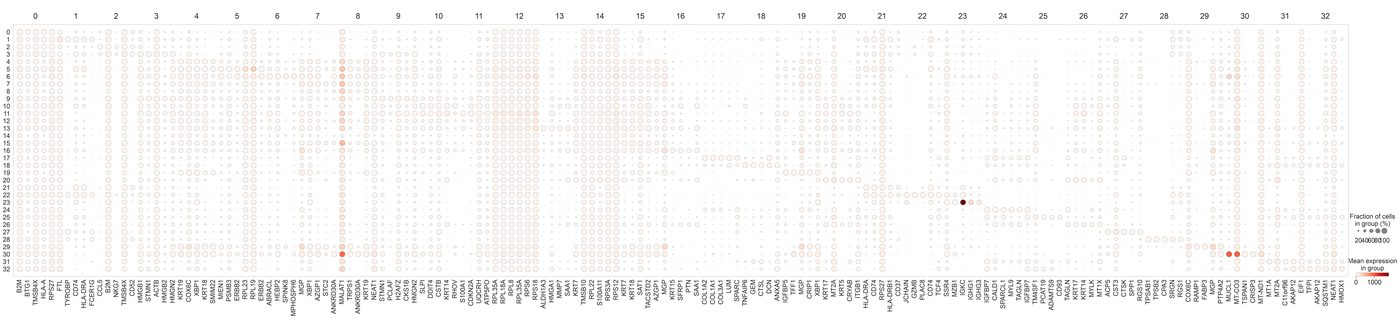

In [58]:
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, swap_axes=False, dendrogram=False,
                                save="_cluster_degs.png")

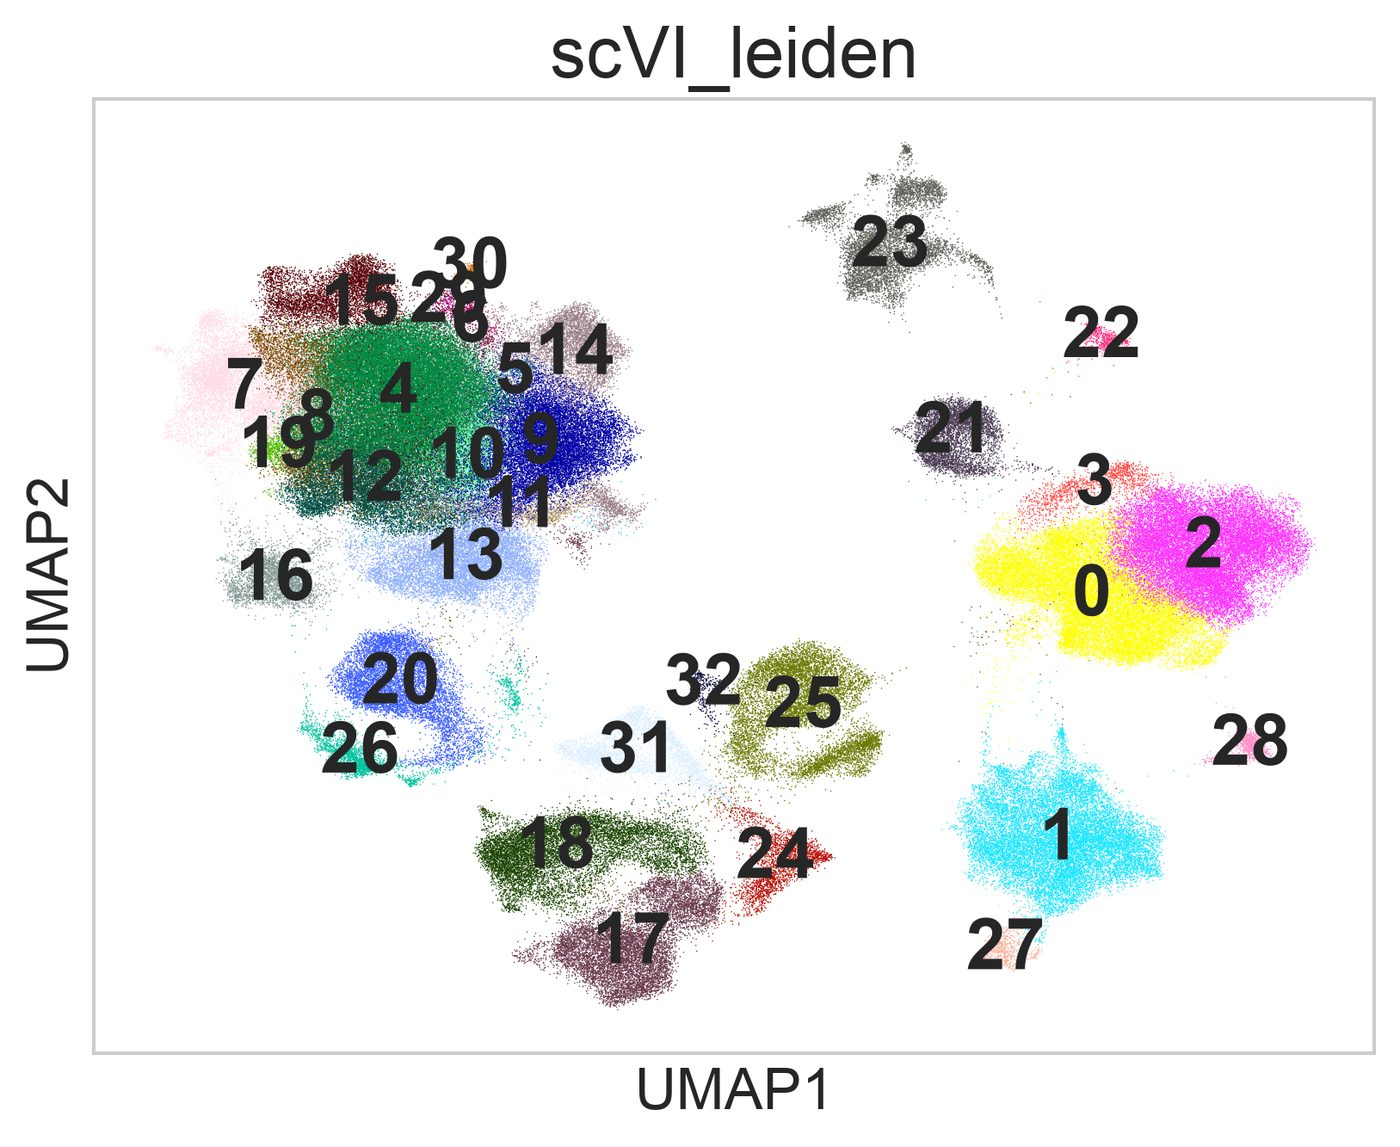

In [59]:
sc.pl.umap(adata, color="scVI_leiden", legend_loc="on data", show=False)
plt.savefig(fig_dir /  "4_Cluster_Numbers.png", dpi=300, bbox_inches="tight")
plt.show()

# Basic Marker Genes 

In [60]:
#keys: cell types or populations, values: lists of marker genes
marker_genes = {
    "T Cells": ["PTPRC", "CD3D", "CD3E", "TRAC"],
    "NK/T Cells": ["NKG7", "GNLY", "KLRD1", "KLRF1"],
    "B Cells": ["CD79A", "CD74", "MS4A1"],
    "Macrophages": ["CD68", "CD14", "ITGAM"],
    "Fibroblasts": ["COL1A1", "CXCL12", "MYL9"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHG1"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],
    "Mast Cells": ["KIT", "CPA3", "TPSAB1"],
    "Dendritic Cells": ["ITGAX", "HLA-DRA", "CD83"],
    "Epithelial Cells": ["EPCAM", "KRT19", "KRT18"],
    "Basal": ["KRT14", "KRT17", "OXTR"],
}

In [61]:
marker_genes_in_data = {}
for ct, markers in marker_genes.items():
    markers_found = []
    for marker in markers:
        if marker in adata.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [62]:
marker_genes = {
    "T cells":            ["PTPRC", "CD3D", "CD3E", "CD3G", "TRAC", "IL7R", "CD8A"],
    "NK cells":           ["KLRF1", "NCR1", "FCER1G", "TYROBP", "NKG7", "GNLY", "KLRD1"],
    "B cells":            ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Plasma cells":       ["MZB1", "JCHAIN", "IGHG1", "XBP1", "DERL3"],
    "Macrophages":        ["CD68", "CD14", "ITGAM", "LYZ", "AIF1", "CSF1R"],
    "SPP1+ macrophages":  ["SPP1", "ACP5", "MMP9", "CTSK"],
    "Dendritic cells":    ["ITGAX", "CD1C", "CLEC9A", "CD83"],
    "pDC":                ["IRF7", "IRF8", "TCF4", "GZMB", "LILRA4", "PLAC8"],
    "Mast cells":         ["KIT", "CPA3", "TPSAB1", "TPSB2", "MS4A2"],
    "Fibroblasts":        ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "PDGFRA"],
    "Perivascular":       ["ACTA2", "RGS5", "PDGFRB", "MYH11", "TAGLN"],
    "Endothelial":        ["PECAM1", "VWF", "CDH5", "CLDN5"],
    "Lymphatic":          ["CCL21", "PDPN", "PROX1", "LYVE1"],
    "Epithelial":         ["EPCAM", "KRT8", "KRT18", "KRT19"],
    "Basal":              ["KRT14", "KRT5", "KRT17", "TP63", "MYLK", "OXTR"],
    "Luminal progenitor": ["ALDH1A3", "KIT", "ELF5", "SLPI", "LTF", "KRT15"],
    "Mature luminal":     ["ESR1", "PGR", "FOXA1", "ANKRD30A", "AREG", "TFF1", "GATA3"],
    "Ciliated":           ["FOXJ1", "TPPP3", "CAPS", "FAM183A", "RSPH1", "PIFO"],
    "Cycling":            ["MKI67", "TOP2A", "CCNB1"],
}

available = {k: [g for g in v if g in adata.var_names] for k, v in marker_genes.items()}
missing   = {k: [g for g in v if g not in adata.var_names] for k, v in marker_genes.items()}
print("missing:", {k: v for k, v in missing.items() if v})


missing: {}


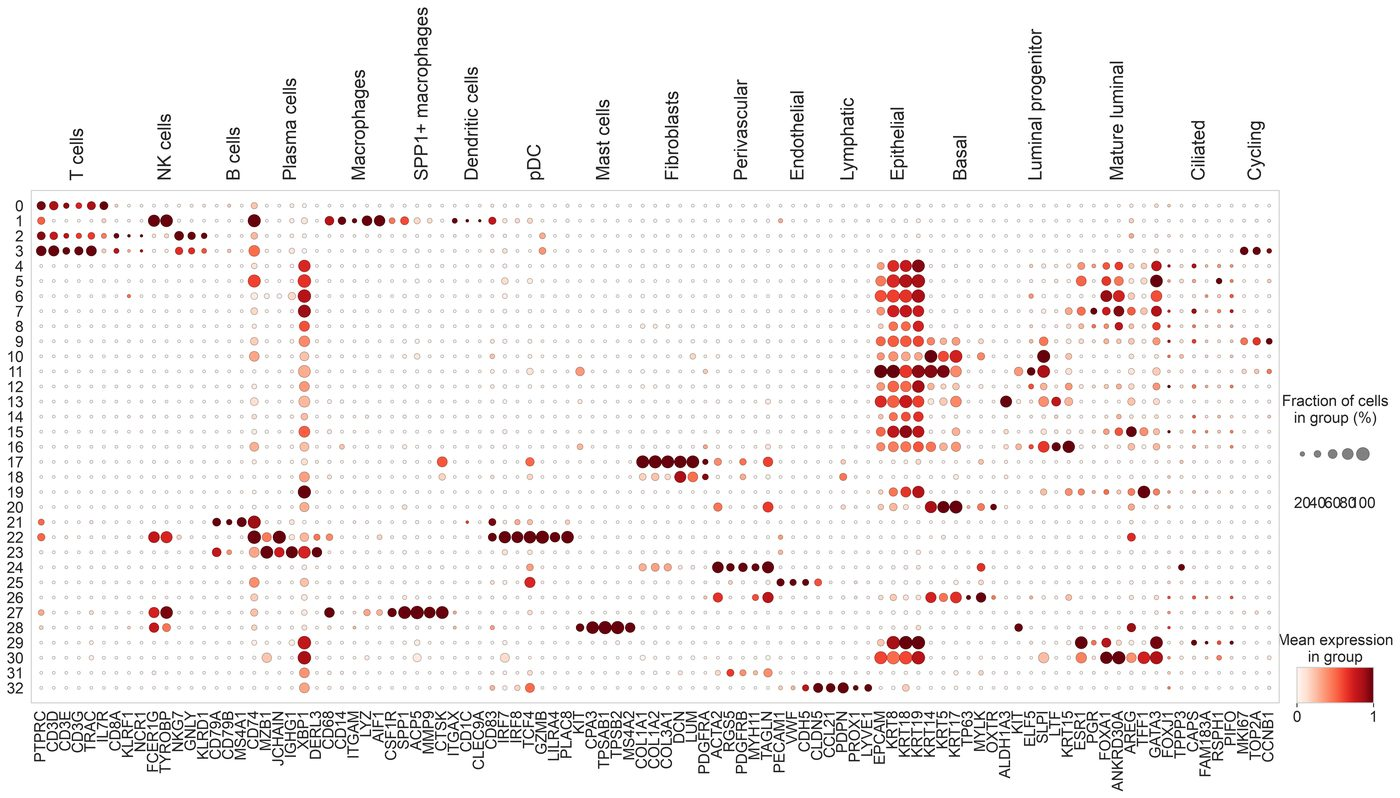

In [63]:
sc.pl.dotplot(adata, available, groupby="scVI_leiden", layer="log1p",
              standard_scale="var", smallest_dot=10, dendrogram=False,
              figsize=[26, 10], save="_markers_all.png")


In [64]:
print(adata.obs.groupby("scVI_leiden")[["pct_counts_mt", "pct_counts_ribo",
                                        "n_genes_by_counts"]].median().round(1).to_string())


             pct_counts_mt  pct_counts_ribo  n_genes_by_counts
scVI_leiden                                                   
0                      7.2        26.700001              493.0
1                      5.0        13.800000              991.0
2                      8.7        22.200001              462.0
3                      5.5        17.100000             1103.5
4                      6.7        25.500000             1427.0
5                     10.9        28.100000             2417.5
6                      8.3        22.500000             3301.0
7                      5.8        23.900000             1581.0
8                      6.2        20.400000              725.0
9                      6.0        22.299999             2185.0
10                     5.1        23.299999             1639.5
11                     1.8        31.000000             3036.0
12                     5.8        38.099998             1725.0
13                     4.9        31.299999            

/var/folders/rh/9t2thrd93sj5g64z90ykd_4r0000gn/T/ipykernel_100/3254679687.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby("scVI_leiden")[["pct_counts_mt", "pct_counts_ribo",


In [65]:
B_plasma_cts = [
    "T Cells",
    "B Cells",
    "Macrophages",
    "Fibroblasts",
    "Plasma Cells",
    "Endothelial Cells",
    "Mast Cells",
    "Dendritic Cells",
    "NK/T Cells"
]

T CELLS:


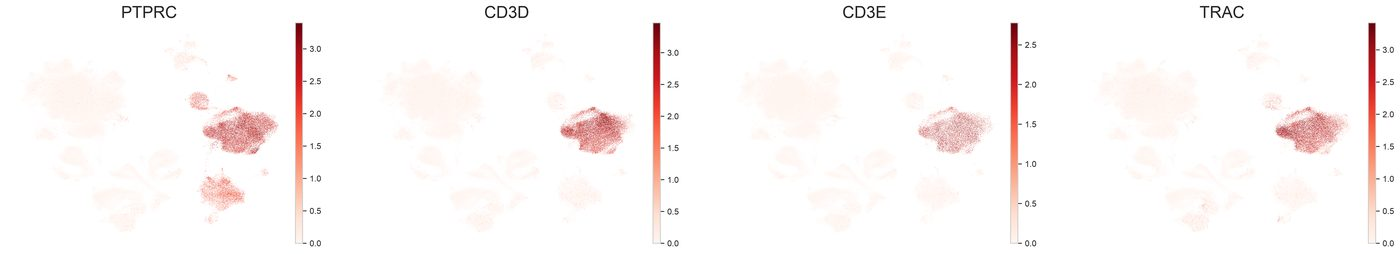





B CELLS:


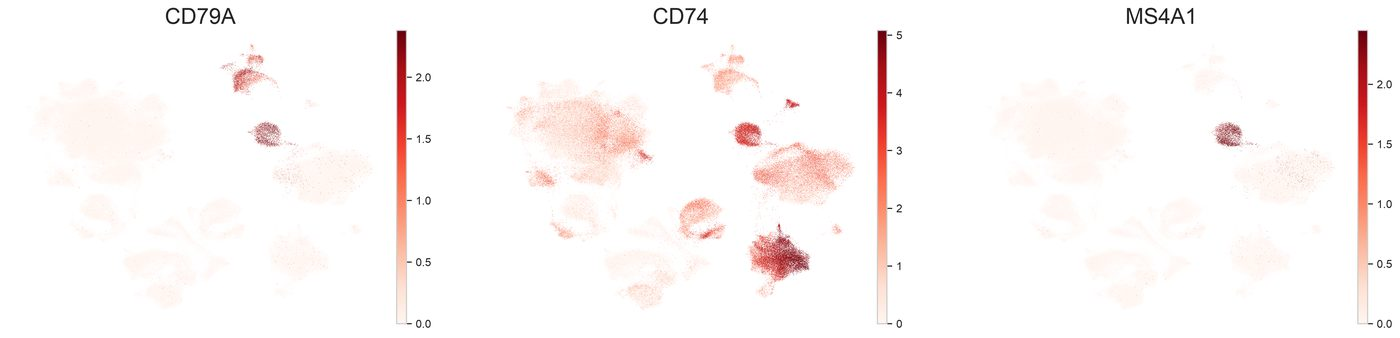





MACROPHAGES:


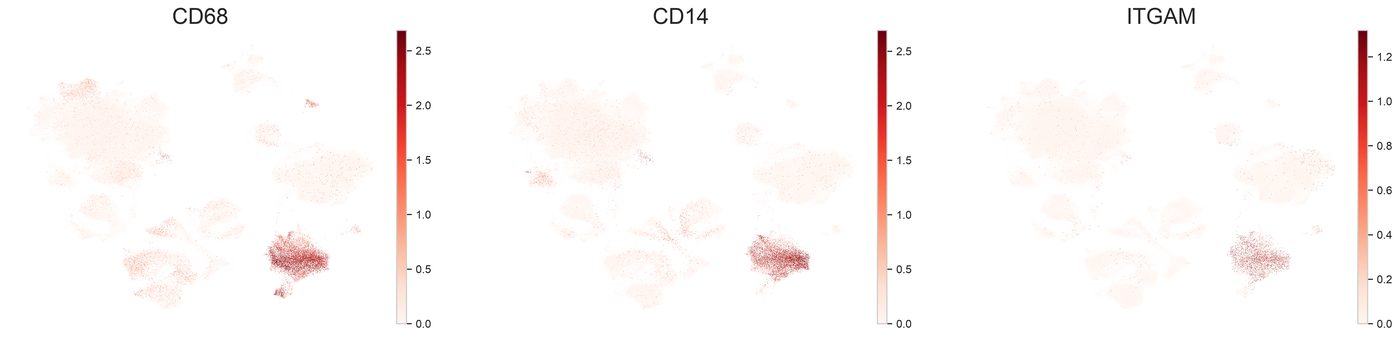





FIBROBLASTS:


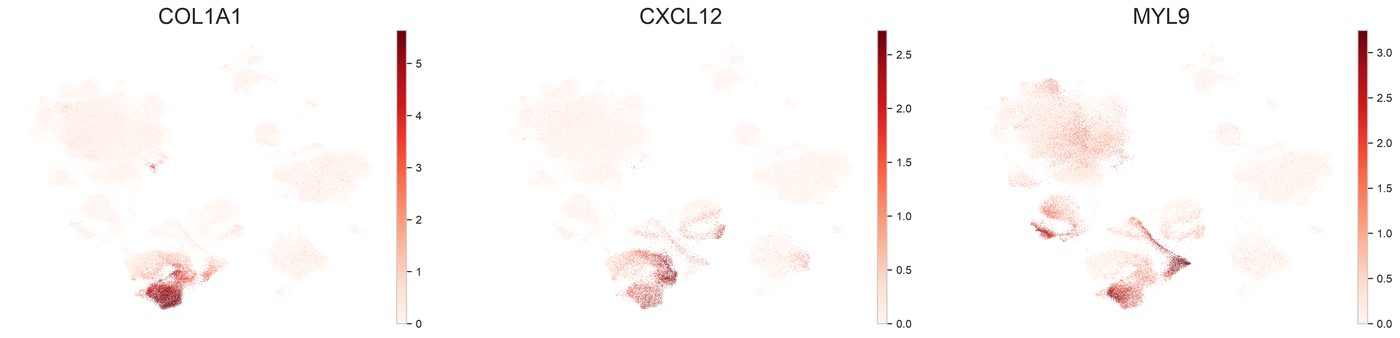





PLASMA CELLS:


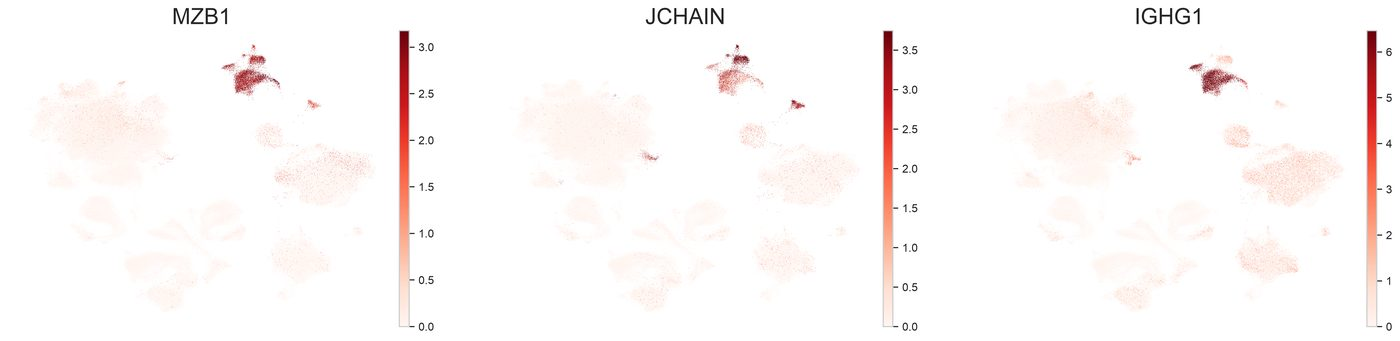





ENDOTHELIAL CELLS:


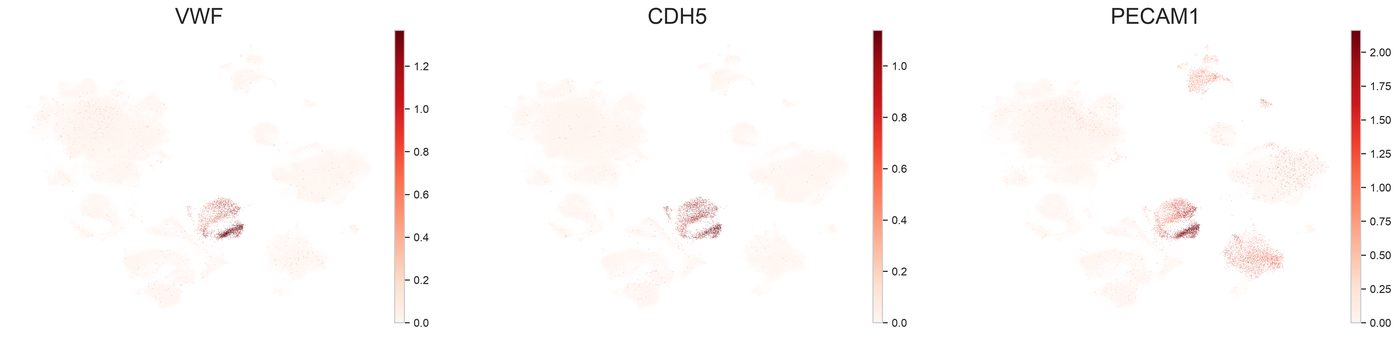





MAST CELLS:


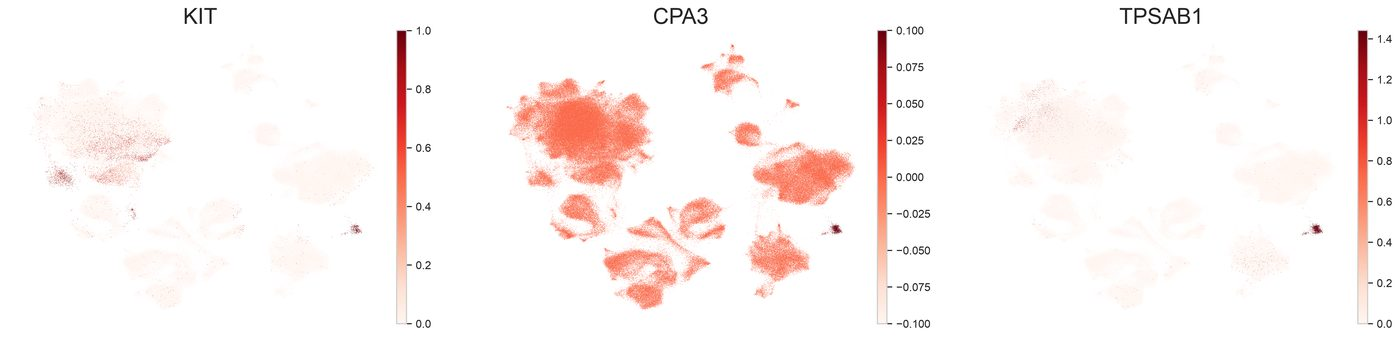





DENDRITIC CELLS:


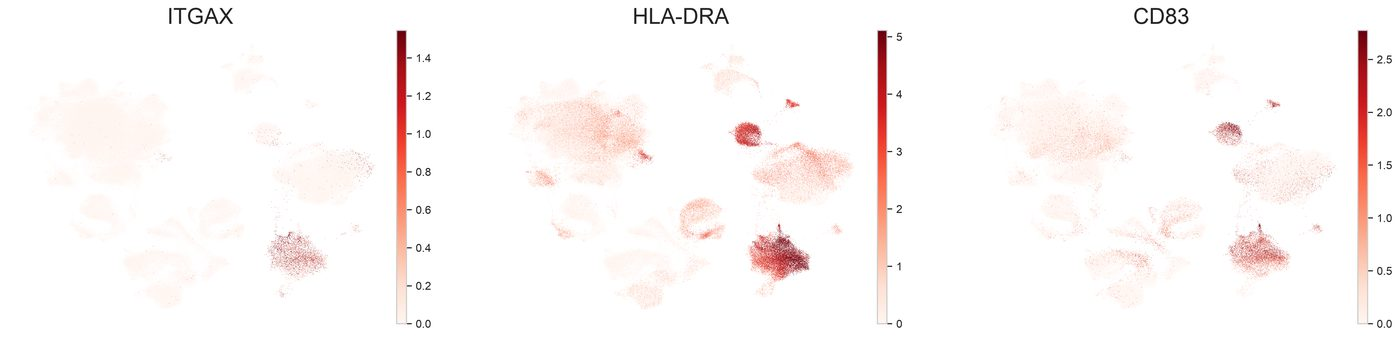





NK/T CELLS:


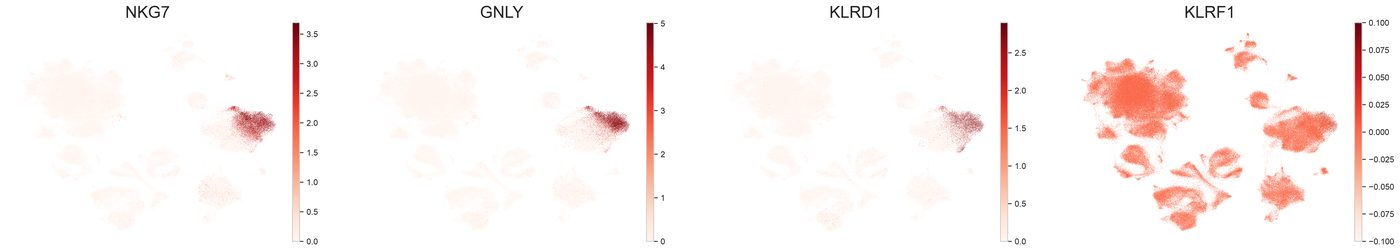

In [66]:
for ct in B_plasma_cts:

    print(f"{ct.upper()}:")

    sc.pl.umap(adata, color=marker_genes_in_data[ct], vmin=0, vmax="p99", sort_order=False,
               layer="log1p", frameon=False, cmap="Reds", show=False)

    plt.savefig(fig_dir / f"umap_markers_{ct.replace('/', '_').replace(' ', '_')}.png",
                dpi=300, bbox_inches="tight")
    plt.show()


In [67]:
B_plasma_markers = {
    ct: [m for m in ct_markers if m in adata.var.index]
    for ct, ct_markers in marker_genes_in_data.items()
    if ct in B_plasma_cts}

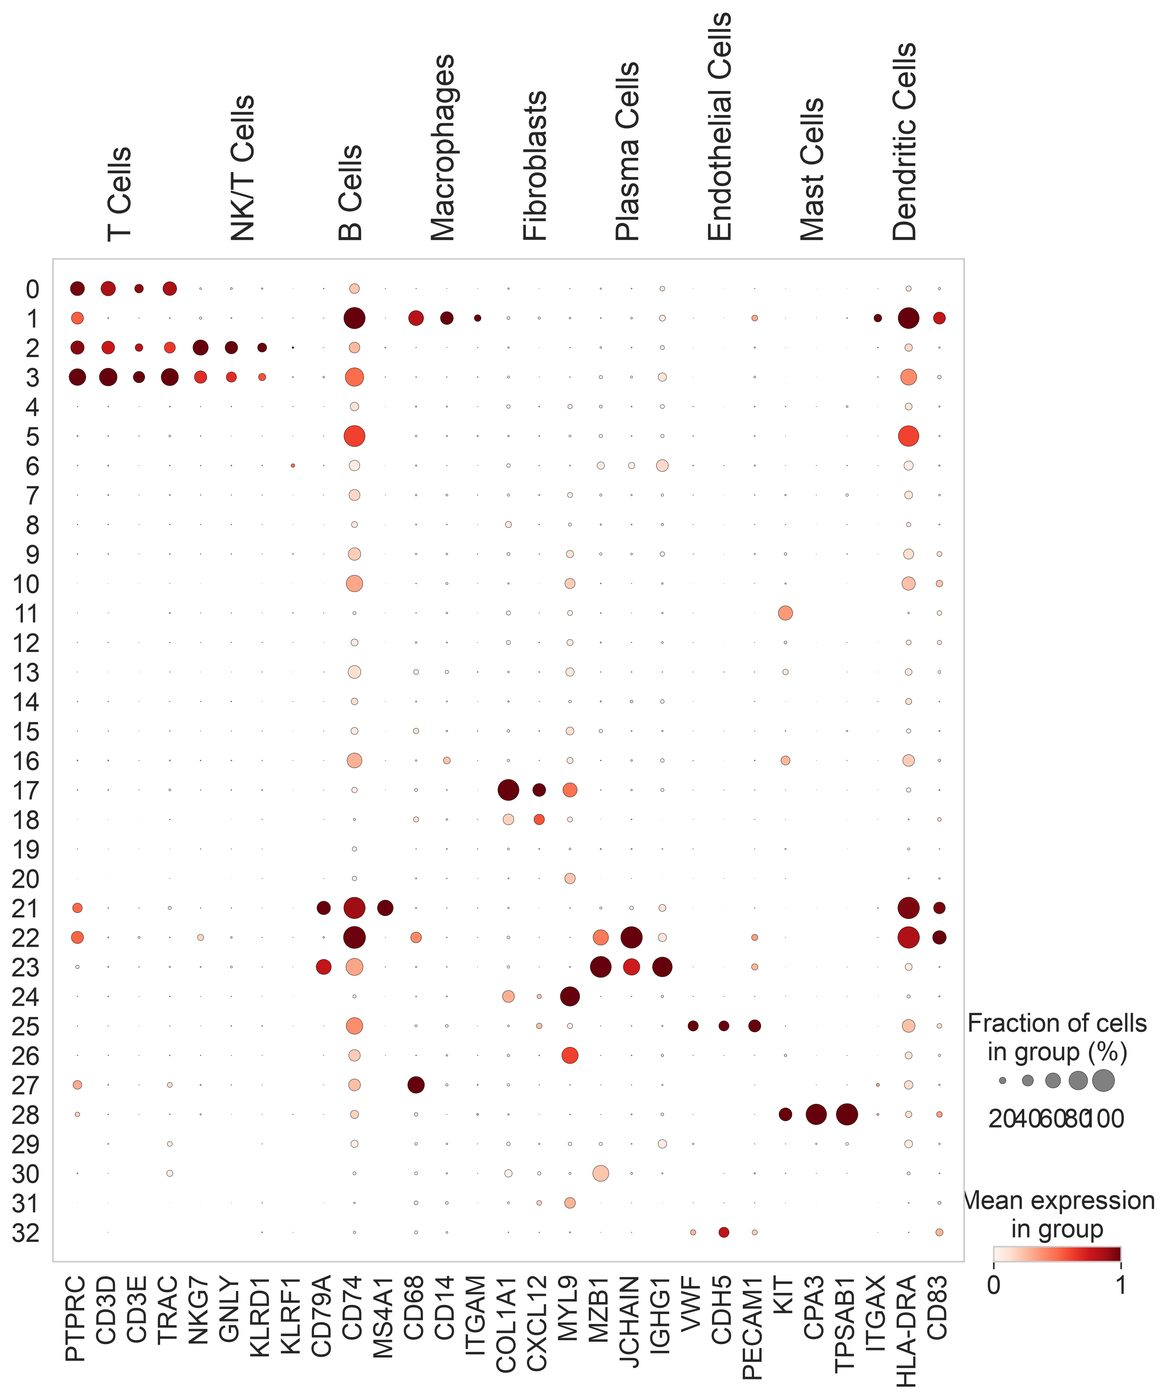

In [68]:
sc.pl.dotplot(adata, groupby="scVI_leiden", var_names=B_plasma_markers, layer='log1p', standard_scale="var", show = False)#standard scale: normalize each gene to range from 0 to 1

plt.savefig(fig_dir / "5_Cell_Type_Marker.png", dpi=300, bbox_inches="tight")
plt.show()

In [69]:
adata

AnnData object with n_obs × n_vars = 238187 × 28552
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable'
    uns: 'neighbors', 'scVI_leiden', 'umap', 'sample_colors', 'condition_colors', 'patient_colors', 'scVI_leiden_colors', 'sample_short_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_scVI', 'X_umap'
    layers: 'counts', 'log1p', 'lognorm'
    obsp: 'distances', 'connectivities'

<Axes: title={'center': 'scVI_leiden'}, xlabel='UMAP1', ylabel='UMAP2'>

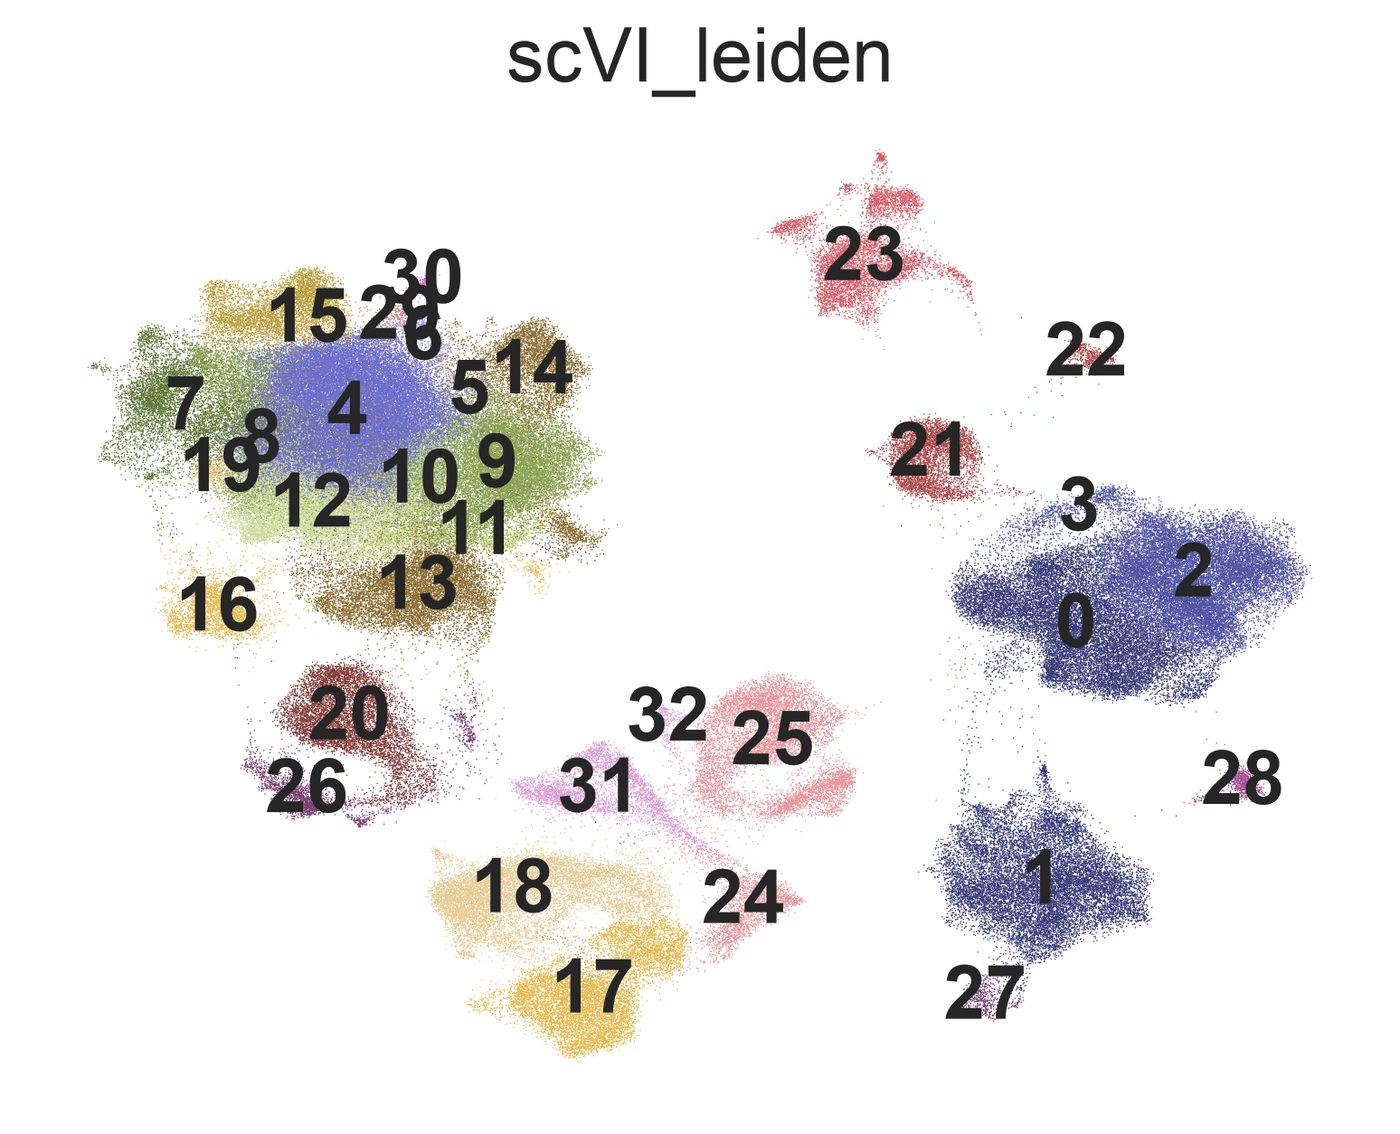

In [70]:
sc.pl.umap(adata, color='scVI_leiden', legend_loc='on data', palette='tab20b' , frameon=False, show=False)

plt.savefig(fig_dir / "umap_leiden_labelled.png", dpi=300, bbox_inches="tight")
plt.show()


In [71]:
#Marker dictionary
marker_genes = {
    "T Cells":           ["PTPRC", "CD3D", "CD3E", "TRAC"],
    "NK/T Cells":        ["NKG7", "GNLY", "KLRD1", "KLRF1"],
    "B Cells":           ["CD79A", "MS4A1", "CD74"],
    "Plasma Cells":      ["MZB1", "JCHAIN", "IGHG1"],
    "Macrophages":       ["CD68", "CD14", "ITGAM"],
    "Dendritic Cells":   ["ITGAX", "HLA-DRA", "CD83"],
    "Mast Cells":        ["KIT", "CPA3", "TPSAB1"],
    "Fibroblasts":       ["COL1A1", "CXCL12", "MYL9"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],
    "Epithelial Cells":  ["EPCAM", "KRT19", "KRT18"],
    "Basal":             ["KRT14", "KRT17", "OXTR"],
}


genes = sorted(set(
    gene
    for gene_list in marker_genes.values()
    for gene in gene_list
))

#keeping only genes present in dataset
genes_present = [g for g in genes if g in adata.var_names]

print(f"{len(genes_present)} / {len(genes)} genes found.")

35 / 35 genes found.


# Celltypist Annotation

In [72]:
import anndata as ad
import celltypist
from celltypist import models

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


### Normalisation

In [73]:
import scipy.sparse as sp


In [74]:
adata_norm = ad.AnnData(X=adata.layers["counts"].copy(), obs=adata.obs.copy(), var=adata.var.copy())

#ensuring CSR sparse
if not sp.issparse(adata_norm.X):
    adata_norm.X = sp.csr_matrix(adata_norm.X)
elif not isinstance(adata_norm.X, sp.csr_matrix):
    adata_norm.X = adata_norm.X.tocsr()

#cellTypist normalization
sc.pp.normalize_total(adata_norm, target_sum=1e4)
sc.pp.log1p(adata_norm)

import gc
gc.collect()

163226

In [75]:
# Ensembl IDs come from the features.tsv the data was aligned against, so the mapping matches the reference exactly. No live query, no extra dependency.
features = pd.read_csv(raw_dir.parent / "features.tsv", sep="\t", header=None,
                       names=["gene_id", "symbol", "feature_type"])
symbol_to_ensembl = dict(zip(features["symbol"], features["gene_id"]))

adata_norm.var["ensembl_id"] = adata_norm.var_names.map(symbol_to_ensembl)
n_mapped = adata_norm.var["ensembl_id"].notna().sum()
print(f"mapped {n_mapped:,} / {adata_norm.n_vars:,} genes to Ensembl IDs")


mapped 28,534 / 28,552 genes to Ensembl IDs


### Model: Pal

In [76]:
import torch
use_gpu = torch.backends.mps.is_available() or torch.cuda.is_available()

#Pal model needs Ensembl IDs as var_names
mask = adata_norm.var["ensembl_id"].notna()
adata_pal = adata_norm[:, mask].copy()#subset, keep norm+log1p
adata_pal.var_names = adata_pal.var["ensembl_id"].astype(str)


In [77]:

pred_pal = celltypist.annotate(
    adata_pal,
    model=models.Model.load(str(project / "Data" / "model_from_pal.pkl")),
    majority_voting=False,
)

🔬 Input data has 238187 cells and 28534 genes
🔗 Matching reference genes in the model
🧬 1395 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


In [ ]:
del adata_pal
gc.collect()

113

In [79]:
del adata_norm
gc.collect()

0

In [80]:
adata.obs["celltypist_pal_label"]        = pred_pal.predicted_labels["predicted_labels"].values
adata.obs["celltypist_pal_conf"]         = pred_pal.probability_matrix.max(axis=1).values

# adata.obs["celltypist_immunehigh_label"] = pred_immunehigh.predicted_labels["majority_voting"].values adata.obs["celltypist_immunehigh_conf"]  = pred_immunehigh.probability_matrix.max(axis=1).values

# adata.obs["celltypist_immunelow_label"]  = pred_immunelow.predicted_labels["majority_voting"].values adata.obs["celltypist_immunelow_conf"]   = pred_immunelow.probability_matrix.max(axis=1).values

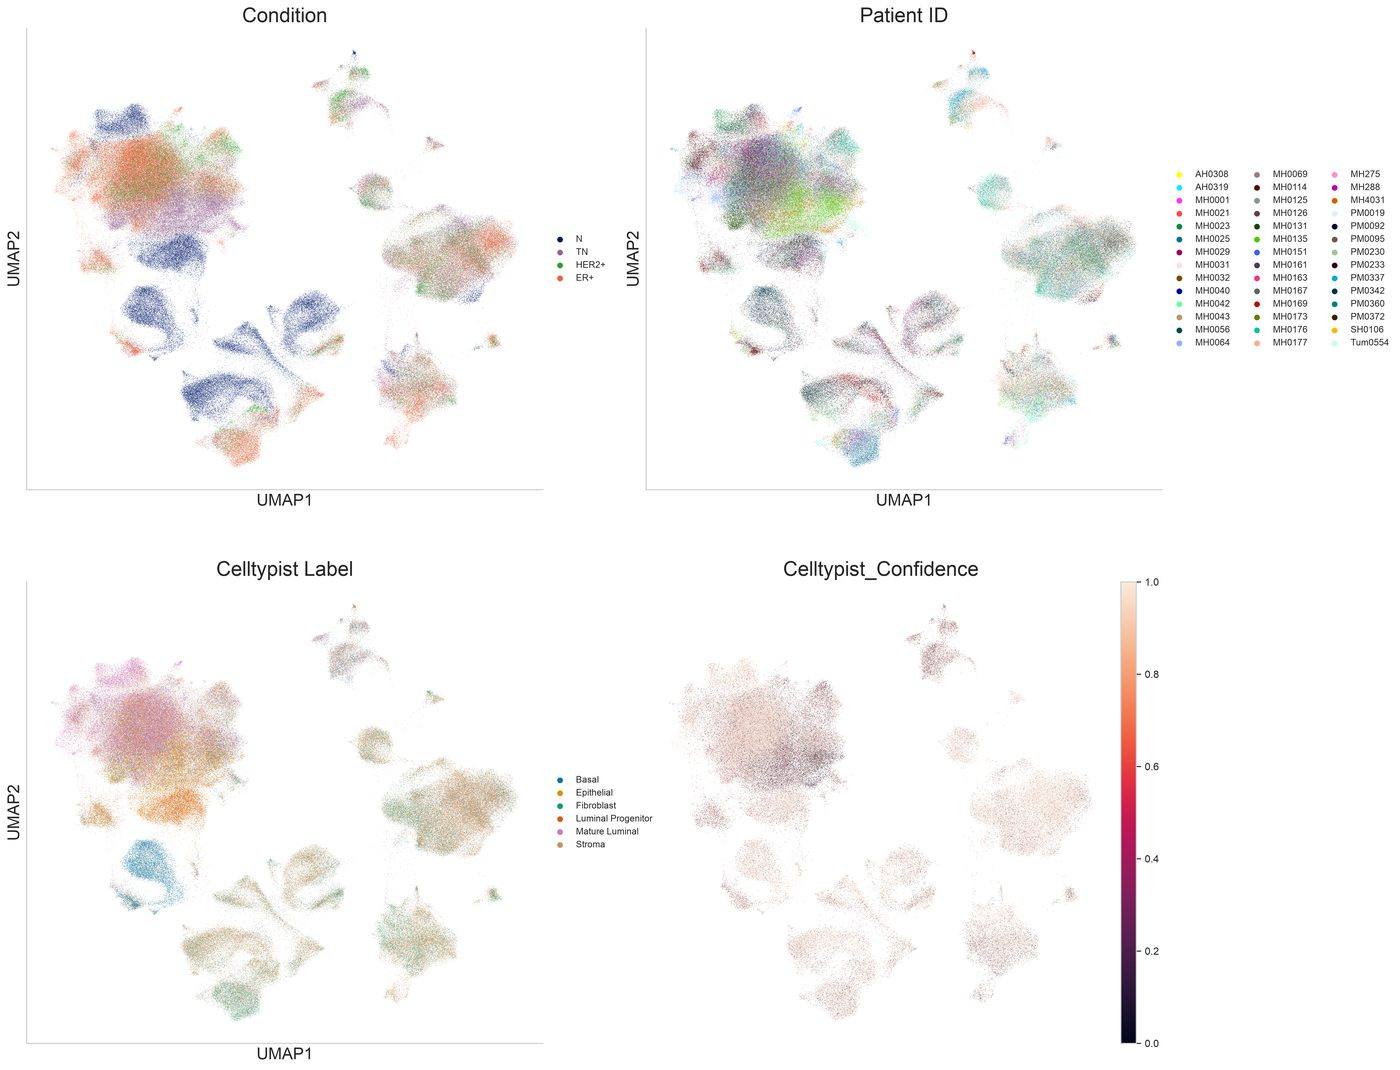

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
axes = axes.flatten()

#a Condition
sc.pl.umap(adata, color="condition", ax=axes[0], layer="log1p", show=False)
axes[0].set_title("Condition")

#b Patient
sc.pl.umap(adata, color="patient", ax=axes[1], layer="log1p", show=False)
axes[1].set_title("Patient ID")

#c Celltypist label
sc.pl.umap(adata, color="celltypist_pal_label", ax=axes[2], layer="log1p",show=False)
axes[2].set_title("Celltypist Label")

#d CNV Clusters
sc.pl.umap(adata, color="celltypist_pal_conf", frameon=False, ax=axes[3], layer="log1p", show=False)
axes[3].set_title("Celltypist_Confidence")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.savefig(fig_dir / "6_FIN_CellTypes.png", dpi=300, bbox_inches="tight")
plt.show()

<Axes: title={'center': 'scVI_leiden'}, xlabel='UMAP1', ylabel='UMAP2'>

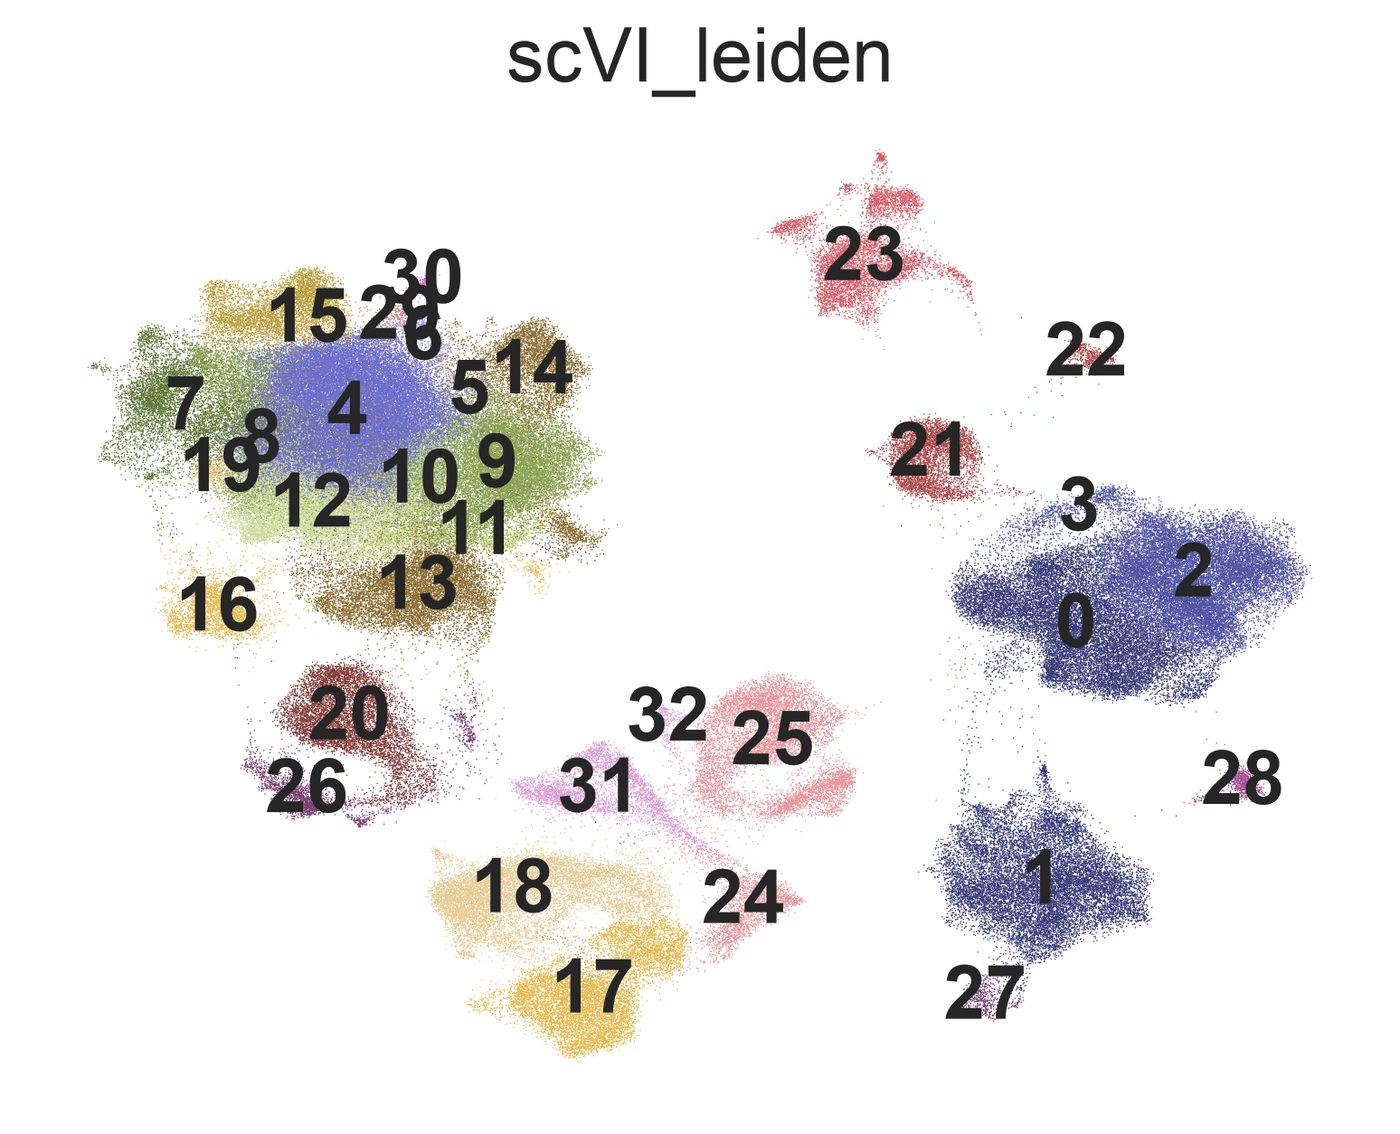

In [82]:
sc.pl.umap(adata, color='scVI_leiden', legend_loc='on data', palette='tab20b' , frameon=False, show=False)

plt.savefig(fig_dir / "umap_leiden_labelled_postfilter.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
cl_annotation = {
    # immune
    "0":  "T Cells",
    "3":  "T Cells",                        # proliferating: CORO1A + STMN1/HMGB2
    "2":  "T/NK Cells",
    "1":  "Macrophages",
    "27": "Macrophages",                    # ACP5/CTSK/MMP9/SPP1, osteoclast-like
    "21": "B Cells",
    "22": "Dendritic Cells",                # pDC: LILRA4, IRF7, GZMB, CD1C-negative
    "23": "Plasma Cells",
    "28": "Mast Cells",

    # stromal / vascular
    "17": "Fibroblasts",
    "18": "Fibroblasts",
    "24": "Perivascular",
    "31": "Perivascular",                   # metallothionein-high, weak RGS5/PDGFRB
    "25": "Endothelial",
    "32": "Endothelial: Lymphatic",         # PDPN, ANGPT2, TFPI

    # epithelial
    "10": "Epithelial: Basal",              # KRT14 3.44, KRT5 1.45
    "20": "Epithelial: Basal",
    "26": "Epithelial: Basal",              # + MYLK/ACTA2, myoepithelial
    "11": "Epithelial: Luminal Progenitor",
    "16": "Epithelial: Luminal Progenitor",
    "4":  "Epithelial: Mature Luminal",     # GATA3/TFF3/AZGP1/TRPS1
    "7":  "Epithelial: Mature Luminal",     # ANKRD30A/AGR2/STC2
    "8":  "Epithelial: Mature Luminal",
    "19": "Epithelial: Mature Luminal",
    "29": "Epithelial: Mature Luminal",     # ESR1
    "9":  "Epithelial: Cycling",            # STMN1/PCLAF/UBE2C
    "5":  "Epithelial",                     # ERBB2/MIEN1/CDK12/PSMB3 = 17q12 amplicon
    "6":  "Epithelial",                     # ERBB2/MIEN1, same amplicon
    "12": "Epithelial",                     # ribo 38.1% but KRT19 2.79 - see note
    "13": "Epithelial",
    "14": "Epithelial",
    "15": "Epithelial",
    "30": "Epithelial: Mature Luminal",    # SCGB2A2/SCGB1D2/MUCL1/CRISP3 high; 18.9% MT
}


In [84]:
cross = pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"], normalize="index")
(100 * cross).round(1)


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
0,4.3,3.1,22.2,5.8,4.5,60.1
1,3.7,6.0,24.4,1.2,1.2,63.5
2,4.4,2.8,10.2,3.9,5.2,73.6
3,3.7,3.0,17.6,5.4,5.0,65.2
4,5.1,24.0,2.0,5.3,56.8,6.8
5,2.6,16.8,1.5,3.8,66.1,9.2
6,12.6,15.9,0.1,4.7,57.6,9.0
7,4.4,18.6,1.2,4.2,68.4,3.3
8,8.2,19.2,5.7,6.4,53.3,7.2


In [85]:
print(adata.obs.groupby("scVI_leiden")[["pct_counts_mt", "pct_counts_ribo",
                                        "n_genes_by_counts"]].median().round(1).to_string())


             pct_counts_mt  pct_counts_ribo  n_genes_by_counts
scVI_leiden                                                   
0                      7.2        26.700001              493.0
1                      5.0        13.800000              991.0
2                      8.7        22.200001              462.0
3                      5.5        17.100000             1103.5
4                      6.7        25.500000             1427.0
5                     10.9        28.100000             2417.5
6                      8.3        22.500000             3301.0
7                      5.8        23.900000             1581.0
8                      6.2        20.400000              725.0
9                      6.0        22.299999             2185.0
10                     5.1        23.299999             1639.5
11                     1.8        31.000000             3036.0
12                     5.8        38.099998             1725.0
13                     4.9        31.299999            

In [86]:
observed = set(adata.obs["scVI_leiden"].astype(str).unique())
mapped   = set(cl_annotation)
assert observed == mapped, (
    f"clusters with no label: {sorted(observed - mapped)}\n"
    f"labels with no cluster: {sorted(mapped - observed)}")

adata.obs["cl_annotation"] = adata.obs["scVI_leiden"].astype(str).map(cl_annotation)
assert adata.obs["cl_annotation"].notna().all()

In [87]:
for label in ["with", "without"]:
    if label == "with":
        m = adata.obs["cl_annotation"].astype(str).str.startswith(("Epithelial", "mito-high", "ribo-high"))
    else:
        m = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
    sub = adata[m]
    x = {g: np.asarray(sub[:, g].layers["counts"].todense()).ravel() >= 1
         for g in ["ROR1", "EGFR", "EPCAM", "ERBB2"]}
    dp = (x["ROR1"] & x["EGFR"]).sum()
    print(f"{label:8s} n={sub.n_obs:7,}  ROR1+EGFR+ {dp:4d} ({100*dp/sub.n_obs:.3f}%)  "
          f"EPCAM+ERBB2+ {100*(x['EPCAM'] & x['ERBB2']).mean():.2f}%")


with     n=129,599  ROR1+EGFR+  350 (0.270%)  EPCAM+ERBB2+ 18.87%
without  n=129,599  ROR1+EGFR+  350 (0.270%)  EPCAM+ERBB2+ 18.87%


In [88]:
summary = (adata.obs.groupby("cl_annotation")["celltypist_pal_conf"]
                    .agg(["count", "median"]).round(2)
                    .sort_values("median"))
print(summary.to_string())


                                count  median
cl_annotation                                
Epithelial: Cycling             16537    0.67
Epithelial: Luminal Progenitor   4359    0.74
Plasma Cells                     7127    0.83
Mast Cells                        886    0.98
Epithelial                      37923    0.99
Epithelial: Mature Luminal      57480    0.99
B Cells                          4894    1.00
Dendritic Cells                   662    1.00
Endothelial                      9043    1.00
Endothelial: Lymphatic            349    1.00
Epithelial: Basal               13300    1.00
Fibroblasts                     20782    1.00
Macrophages                     16876    1.00
Perivascular                     6445    1.00
T Cells                         20224    1.00
T/NK Cells                      21300    1.00


In [89]:
epi = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
cross = pd.crosstab(adata.obs.loc[epi, "scVI_leiden"],
                    adata.obs.loc[epi, "celltypist_pal_label"], normalize="index")
(100 * cross).round(1)


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
4,5.1,24.0,2.0,5.3,56.8,6.8
5,2.6,16.8,1.5,3.8,66.1,9.2
6,12.6,15.9,0.1,4.7,57.6,9.0
7,4.4,18.6,1.2,4.2,68.4,3.3
8,8.2,19.2,5.7,6.4,53.3,7.2
9,13.0,32.2,2.9,16.2,30.8,4.9
10,4.9,54.0,5.7,20.8,12.5,2.1
11,9.5,35.8,1.8,19.4,25.5,8.1
12,11.2,37.2,2.0,11.3,28.7,9.6


In [90]:
conf  = adata.obs["celltypist_pal_conf"] > 0.5
cross = pd.crosstab(adata.obs["scVI_leiden"],
                    adata.obs["celltypist_pal_label"].astype(str).where(conf, "low confidence"))
(100 * cross.div(cross.sum(axis=1), axis=0)).round(1)


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma,low confidence
scVI_leiden,,,,,,,
0,3.0,1.3,19.0,4.8,3.4,55.3,13.2
1,2.1,2.4,18.8,0.7,0.7,54.2,21.1
2,3.2,1.3,8.4,3.3,3.9,69.2,10.6
3,2.5,1.0,14.2,4.5,3.9,59.2,14.8
4,3.5,12.5,1.3,3.8,48.9,5.0,25.0
5,1.5,3.1,0.8,3.3,51.5,5.9,33.9
6,9.3,4.0,0.1,3.1,44.2,5.7,33.6
7,3.4,10.3,0.9,3.4,61.5,2.4,18.2
8,6.1,9.2,3.9,4.7,45.7,5.1,25.4


In [92]:
(adata.obs.groupby("scVI_leiden")["celltypist_pal_conf"]
          .apply(lambda x: (x < 0.5).mean() * 100).round(1)
          .sort_values(ascending=False).head(12))


scVI_leiden
11    73.8
10    53.8
29    50.0
9     46.3
23    39.1
14    36.9
12    35.5
5     33.9
6     33.6
27    33.3
16    33.2
28    31.4
Name: celltypist_pal_conf, dtype: float64

... storing 'cl_annotation' as categorical


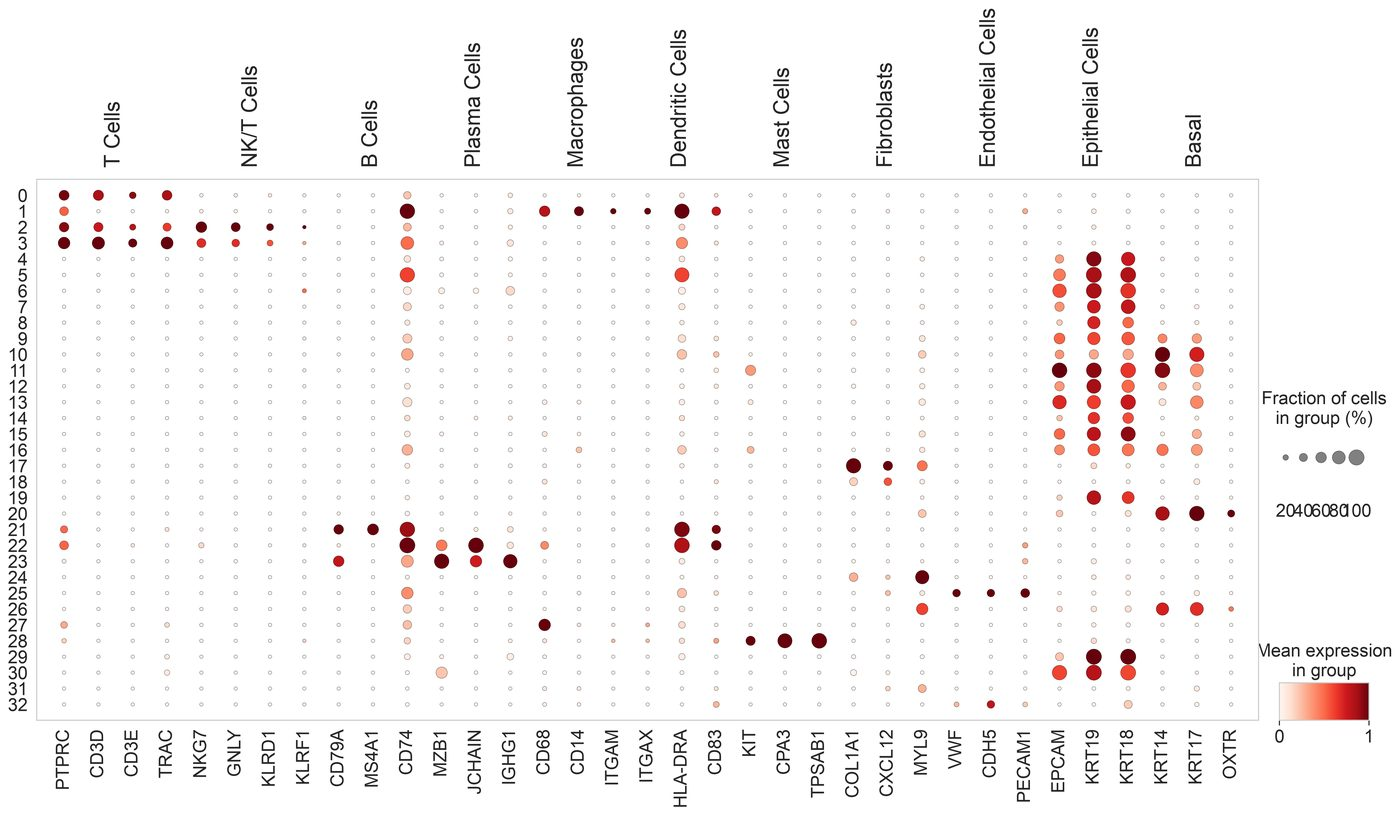

In [93]:
available = {k: [g for g in v if g in adata.var_names] for k, v in marker_genes.items()}
sc.pl.dotplot(adata, available, groupby="scVI_leiden", layer="log1p",
              standard_scale="var", smallest_dot=10, figsize=[22, 9],
              save="_all_clusters_markers.png")


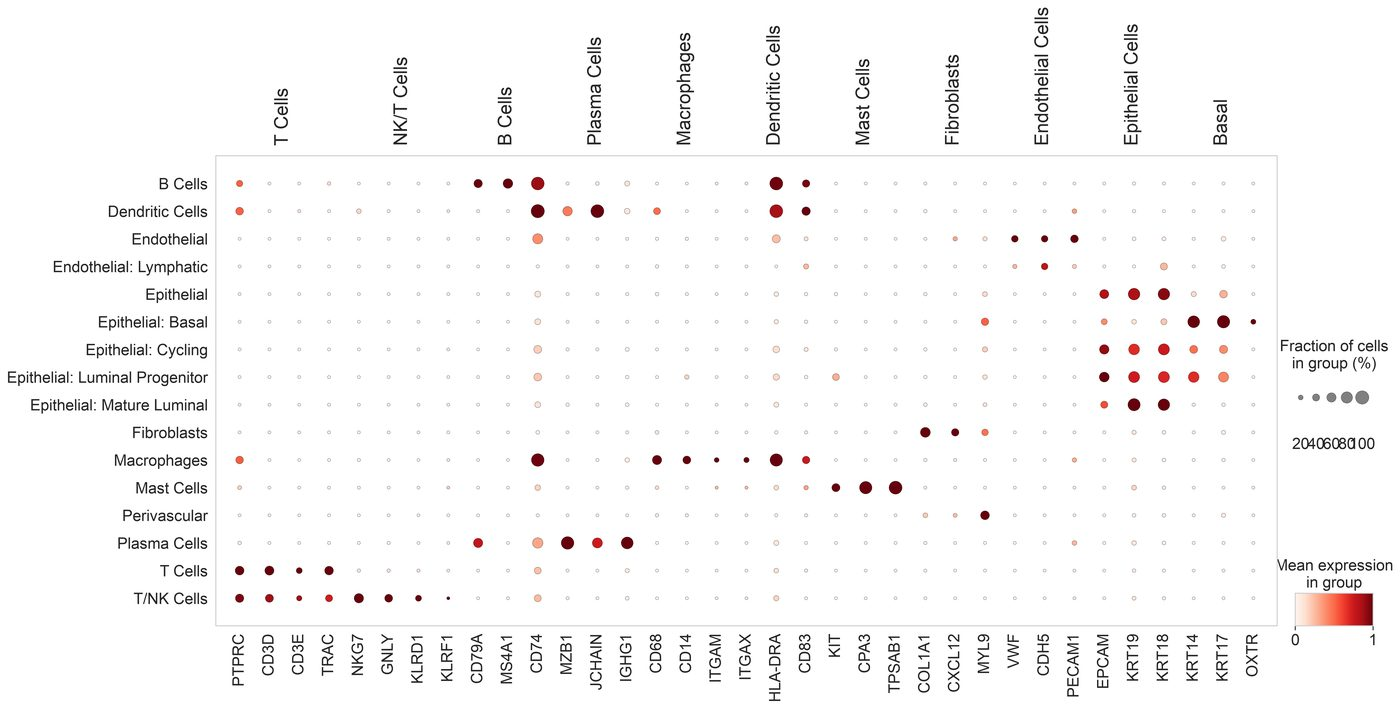

In [94]:
available = {k: [g for g in v if g in adata.var_names] for k, v in marker_genes.items()}
sc.pl.dotplot(adata, available, groupby="cl_annotation", layer="log1p",
              standard_scale="var", smallest_dot=10, figsize=[22, 9],
              save="_all_clusters_markers.png")


In [95]:
epi = adata[adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")]
x = np.asarray(epi[:, "EPCAM"].layers["log1p"].todense()).ravel()
print(f"EPCAM detected in {100*(x>0).mean():.1f}% of the epithelial subset")


EPCAM detected in 48.1% of the epithelial subset


In [96]:
adata.write_h5ad(save_dir / "project_annotated.h5ad", compression="gzip")

# Saving Epithelial Compartment

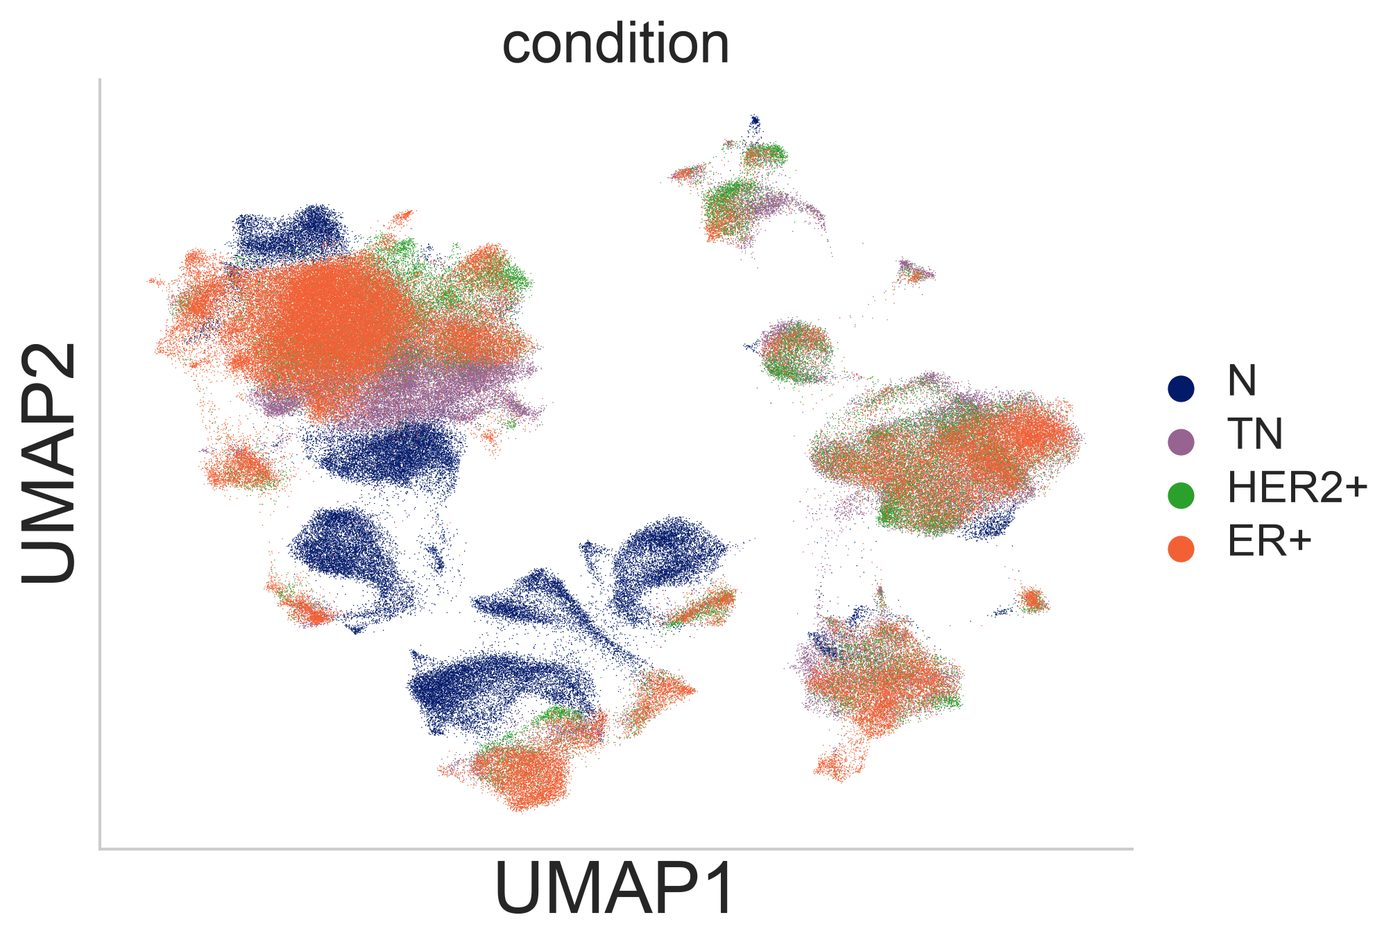

In [97]:
# Desired visual layering: HER2+ drawn first (bottom) TN drawn second ER+ drawn last (top) Keep N separate / draw it first as the bottom layer
plot_order = ["N", "TN", "HER2+", "ER+"]

# Create plotting order
condition_rank = {
    condition: i
    for i, condition in enumerate(plot_order)
}

plot_idx = (
    adata.obs["condition"].map(condition_rank).sort_values().index
)

# Plot reordered cells
sc.pl.umap(
    adata[plot_idx],
    color="condition", palette=condition_palette, ncols=1, vmax="p99", show=False
)
ax = plt.gca()

# Remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep left and bottom spines
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)

# Axis labels
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)

# Tick labels
ax.tick_params(axis="both", labelsize=12)

# Legend
legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)

    # Larger legend markers
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(fig_dir / "umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()

In [98]:
#saving cell barcodes with metadata to CSV
adata.obs[["sample", "condition", "patient", "cl_annotation", "scVI_leiden"]].to_csv(
    df_dir / "cell_metadata.csv")


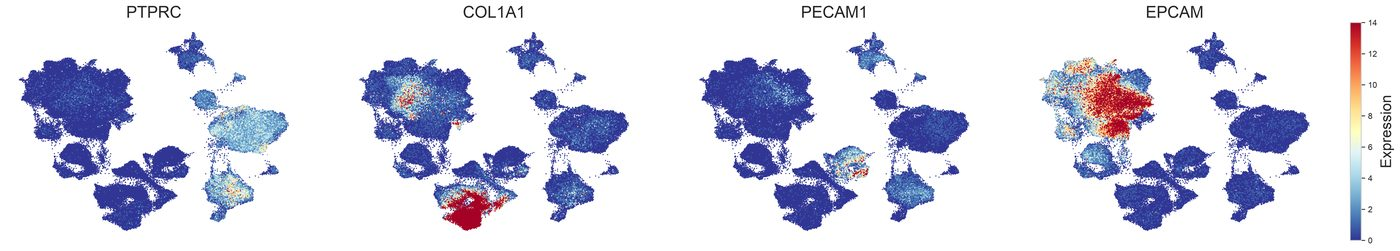

In [99]:
import matplotlib as mpl
import numpy as np
markers = ["PTPRC", "COL1A1", "PECAM1", "EPCAM"]

#computing shared vmax across all genes
vals = np.concatenate([adata[:, g].X.toarray().flatten() for g in markers])

vmax = np.percentile(vals, 99)

#5 UMAP coloured by compartment-defining genes
fig = sc.pl.umap(adata, color=markers, ncols=4, size=8, frameon=False, cmap="RdYlBu_r", vmin=0,
    vmax=vmax, sort_order=True, colorbar_loc=None, wspace=0.15, show=False, return_fig=True)

# Create shared colorbar
norm = mpl.colors.Normalize(vmin=0, vmax=vmax)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="RdYlBu_r")
sm.set_array([])

cbar = fig.colorbar(sm, ax=fig.axes, location="right", fraction=0.03, pad=0.02)

cbar.set_label("Expression", fontsize=18)
plt.savefig(fig_dir / "7_UMAP_marker_panels_BGR_SCALE.png", dpi=600, bbox_inches="tight")
plt.show()

In [100]:
# condition_palette is defined once at the top of the notebook and not redefined here

celltype_palette = {
    # immune
    "T Cells":                        "#2166AC",
    "T/NK Cells":                       "#67A9CF",
    "B Cells":                        "#FFD92F",
    "Plasma Cells":                   "#FF7F00",
    "Macrophages":                    "#33A02C",
    "Dendritic Cells":                "#6A3D9A",
    "Mast Cells":                     "#8C510A",
    # stromal / vascular
    "Fibroblasts":                    "#D73027",
    "Perivascular":                   "#CAB2D6",
    "Endothelial":                    "#F781BF",
    "Endothelial: Lymphatic":         "#FCC5C0",
    # epithelial
    "Epithelial":                     "#00BFC4",
    "Epithelial: Basal":              "#00441B",
    "Epithelial: Luminal Progenitor": "#A6CEE3",
    "Epithelial: Mature Luminal":     "#1F9E89",
    "Epithelial: Ciliated":           "#7FCDBB",
    "Epithelial: Cycling":            "#B2182B",
    # descriptive
    "ribo-high":                 "#CCCCCC",
}

missing = set(adata.obs["cl_annotation"].astype(str).unique()) - set(celltype_palette)
assert not missing, f"palette missing: {missing}"
print(f"palette covers all {adata.obs['cl_annotation'].nunique()} labels")



palette covers all 16 labels


<Axes: title={'center': 'scVI_leiden'}, xlabel='UMAP1', ylabel='UMAP2'>

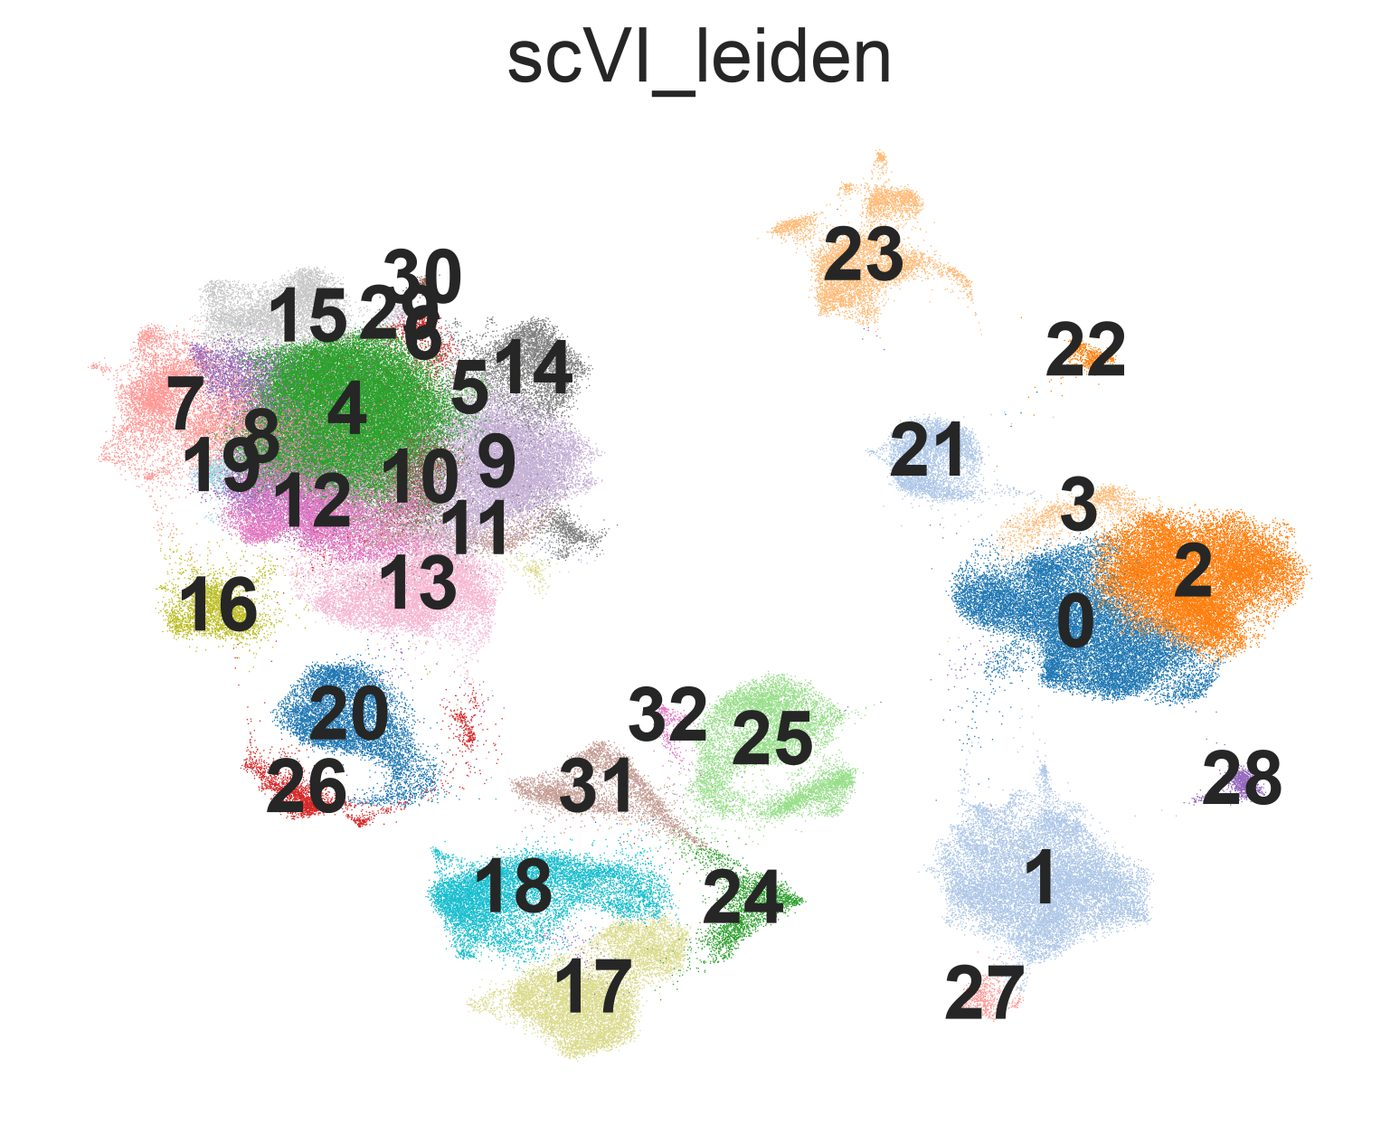

In [101]:
sc.pl.umap(adata, color='scVI_leiden', legend_loc='on data', palette=sns.color_palette("tab20", n_colors=adata.obs['scVI_leiden'].nunique()), frameon=False, show=False)

plt.savefig(fig_dir / "umap_leiden_final.png", dpi=300, bbox_inches="tight")
plt.show()


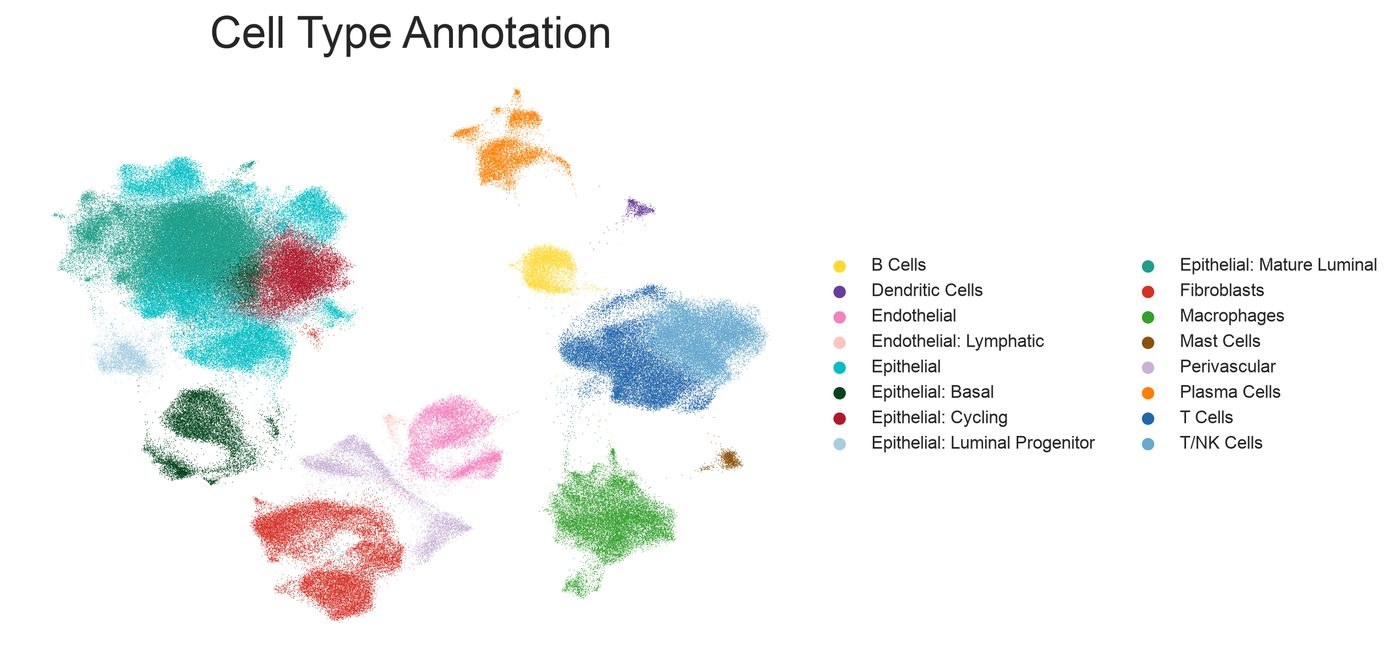

In [102]:
#6 UMAP coloured by Celltype
sc.pl.umap(adata, color="cl_annotation", palette=celltype_palette, layer="log1p", legend_loc="right margin", legend_fontsize=8, title="Cell Type Annotation", frameon=False, show=False)
plt.savefig(fig_dir / "8_Celltypes_N2.png", dpi=300, bbox_inches="tight")

In [103]:
import gc
gc.collect()

59773

In [104]:
# Map clusters to cell-type annotation
assert adata.obs["cl_annotation"].notna().all()

# Extract epithelial cells across all conditions
epithelial_mask = (
    adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
)

epithelial_obs = adata.obs.loc[
    epithelial_mask, ["sample", "condition", "cl_annotation", "scVI_leiden"]].copy()

# Summary
print(f"Epithelial cells: {epithelial_mask.sum():,}")
print("\nCell types:")
print(epithelial_obs["cl_annotation"].value_counts())
print("\nConditions:")
print(epithelial_obs["condition"].value_counts())
print("\nSamples:")
print(epithelial_obs["sample"].value_counts())
# print("\nPatients:") print(epithelial_obs["patient"].value_counts())

# Saving barcodes
epithelial_obs.to_csv(df_dir / "epithelial_barcodes.csv", index=True, index_label="barcode")

Epithelial cells: 129,599

Cell types:
cl_annotation
Epithelial: Mature Luminal        57480
Epithelial                        37923
Epithelial: Cycling               16537
Epithelial: Basal                 13300
Epithelial: Luminal Progenitor     4359
B Cells                               0
Dendritic Cells                       0
Endothelial                           0
Endothelial: Lymphatic                0
Fibroblasts                           0
Macrophages                           0
Mast Cells                            0
Perivascular                          0
Plasma Cells                          0
T Cells                               0
T/NK Cells                            0
Name: count, dtype: int64

Conditions:
condition
ER+      60060
TN       26617
N        26425
HER2+    16497
Name: count, dtype: int64

Samples:
sample
GSM4909282_TN-MH0135         12274
GSM4909306_ER-MH0029-9C       5841
GSM4909299_ER-MH0114-T3       5777
GSM4909297_ER-MH0125          5408
GSM4909304_ER-M

In [105]:
(pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"])
   .to_csv(df_dir / "cluster_vs_celltypist.csv"))

In [106]:
#Saving Table for Barplot (Celltype Distribution per Sample)
barcode_df = adata.obs[["sample", "condition", "patient", "cl_annotation"]].copy()
barcode_df.index.name = "barcode"
barcode_df.to_csv(df_dir / "barcode_table.csv")

### Supplementary Figure 1b, 1c, 1e

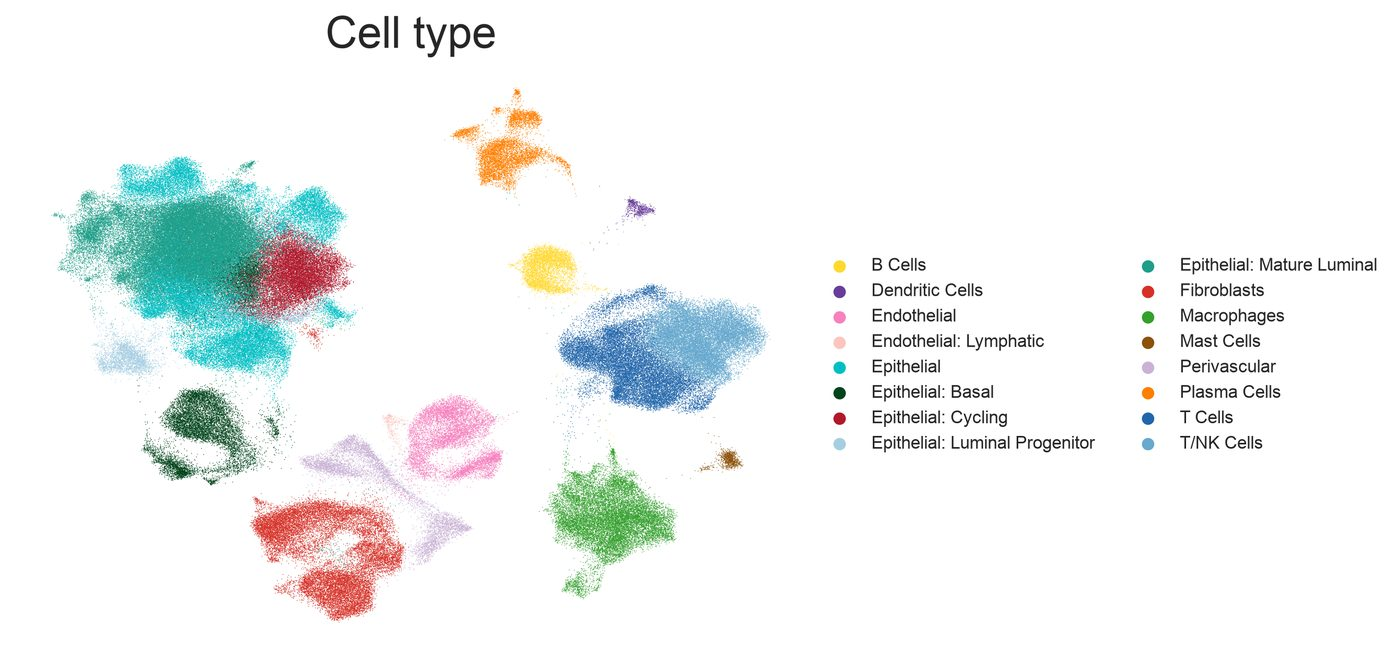

In [107]:
# Supplementary Figure 1b - cell types on the atlas UMAP
sc.pl.umap(adata, color="cl_annotation", palette=celltype_palette,
           legend_loc="right margin", legend_fontsize=8, frameon=False,
           title="Cell type", show=False)

plt.savefig(fig_dir / "supp1b_celltypes.png", dpi=300, bbox_inches="tight")
plt.show()

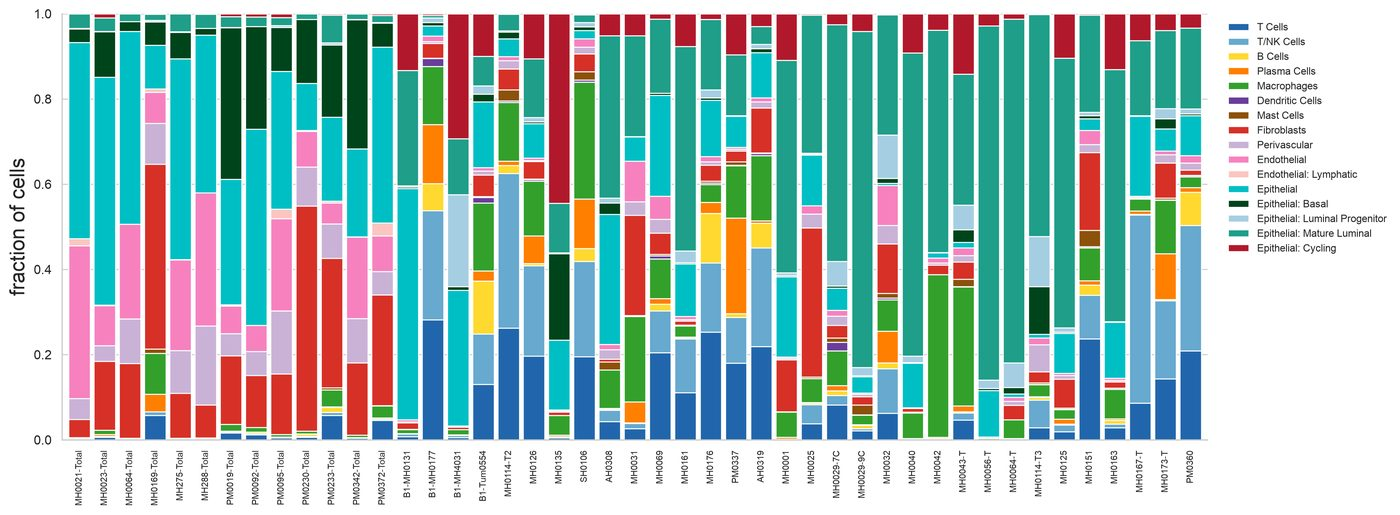

In [ ]:
#  cell-type composition of every sample, samples grouped by condition
comp = pd.crosstab(adata.obs["sample_short"], adata.obs["cl_annotation"], normalize="index")

order = (adata.obs[["sample_short", "condition"]].drop_duplicates()
         .assign(rank=lambda d: d["condition"].map({"N": 0, "TN": 1, "HER2+": 2, "ER+": 3}))
         .sort_values(["rank", "sample_short"])["sample_short"])

comp = comp.loc[order]
cols = [c for c in celltype_palette if c in comp.columns] + \
       [c for c in comp.columns if c not in celltype_palette]
comp = comp[cols]

fig, ax = plt.subplots(figsize=(16, 6))
comp.plot(kind="bar", stacked=True, width=0.85, ax=ax,
          color=[celltype_palette.get(c, "lightgrey") for c in comp.columns])

ax.set_xlabel("")
ax.set_ylabel("fraction of cells")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig(fig_dir / "supp1c_celltype_per_sample.png", dpi=300, bbox_inches="tight")
plt.show()

comp.to_csv(df_dir / "celltype_fraction_per_sample.csv")

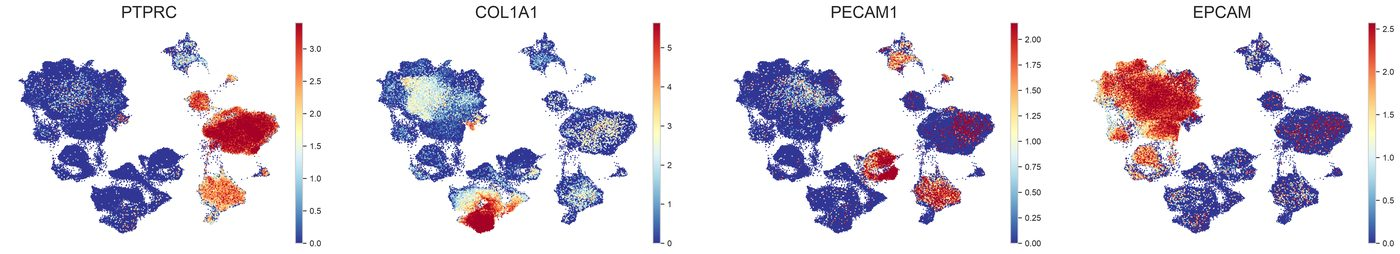

In [109]:
# Supplementary Figure 1e - lineage markers on the atlas UMAP
sc.pl.umap(adata, color=["PTPRC", "COL1A1", "PECAM1", "EPCAM"], ncols=4,
           layer="log1p", cmap="RdYlBu_r", vmin=0, vmax="p99", size=8,
           frameon=False, show=False)

plt.savefig(fig_dir / "supp1e_marker_umaps.png", dpi=300, bbox_inches="tight")
plt.show()

In [110]:
genes_present = [g for g in sorted({g for v in marker_genes.values() for g in v})
                 if g in adata.var_names]

In [111]:
#Saving Table for PieChart (Epithelial Cells per Sample/Condition)
adata_sub = adata[:, genes_present].copy()
X = adata_sub.layers["log1p"]

df = pd.DataFrame(
    X.toarray() if hasattr(X, "toarray") else X,
    index=adata_sub.obs_names,
    columns=genes_present
)

#adding metadata
df["cluster"] = adata_sub.obs["scVI_leiden"].values
df["cell_type"] = adata_sub.obs["cl_annotation"].values

df.index.name = "barcode"
tmp = df.reset_index()
#Table for Dotplot (Celltype Markers)
long_df = tmp.melt(
    id_vars=["barcode", "cluster", "cell_type"],
    var_name="gene",
    value_name="expression"
)


long_df.to_csv(df_dir / "dotplot_long_format.csv", index=False)

In [112]:
# free the large intermediates; nothing below uses them
del adata_sub
gc.collect()

20100

In [113]:
print(df.index.name)
print(df.columns.tolist())

barcode
['CD14', 'CD3D', 'CD3E', 'CD68', 'CD74', 'CD79A', 'CD83', 'CDH5', 'COL1A1', 'CPA3', 'CXCL12', 'EPCAM', 'GNLY', 'HLA-DRA', 'IGHG1', 'ITGAM', 'ITGAX', 'JCHAIN', 'KIT', 'KLRD1', 'KLRF1', 'KRT14', 'KRT17', 'KRT18', 'KRT19', 'MS4A1', 'MYL9', 'MZB1', 'NKG7', 'OXTR', 'PECAM1', 'PTPRC', 'TPSAB1', 'TRAC', 'VWF', 'cluster', 'cell_type']


In [114]:
epi_mask = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
epi = adata[epi_mask].copy()
epi.write_h5ad(save_dir / "epithelial.h5ad", compression="gzip")
print("epithelial:", epi.shape)


epithelial: (129599, 28552)


### Supplementary Figure 1g

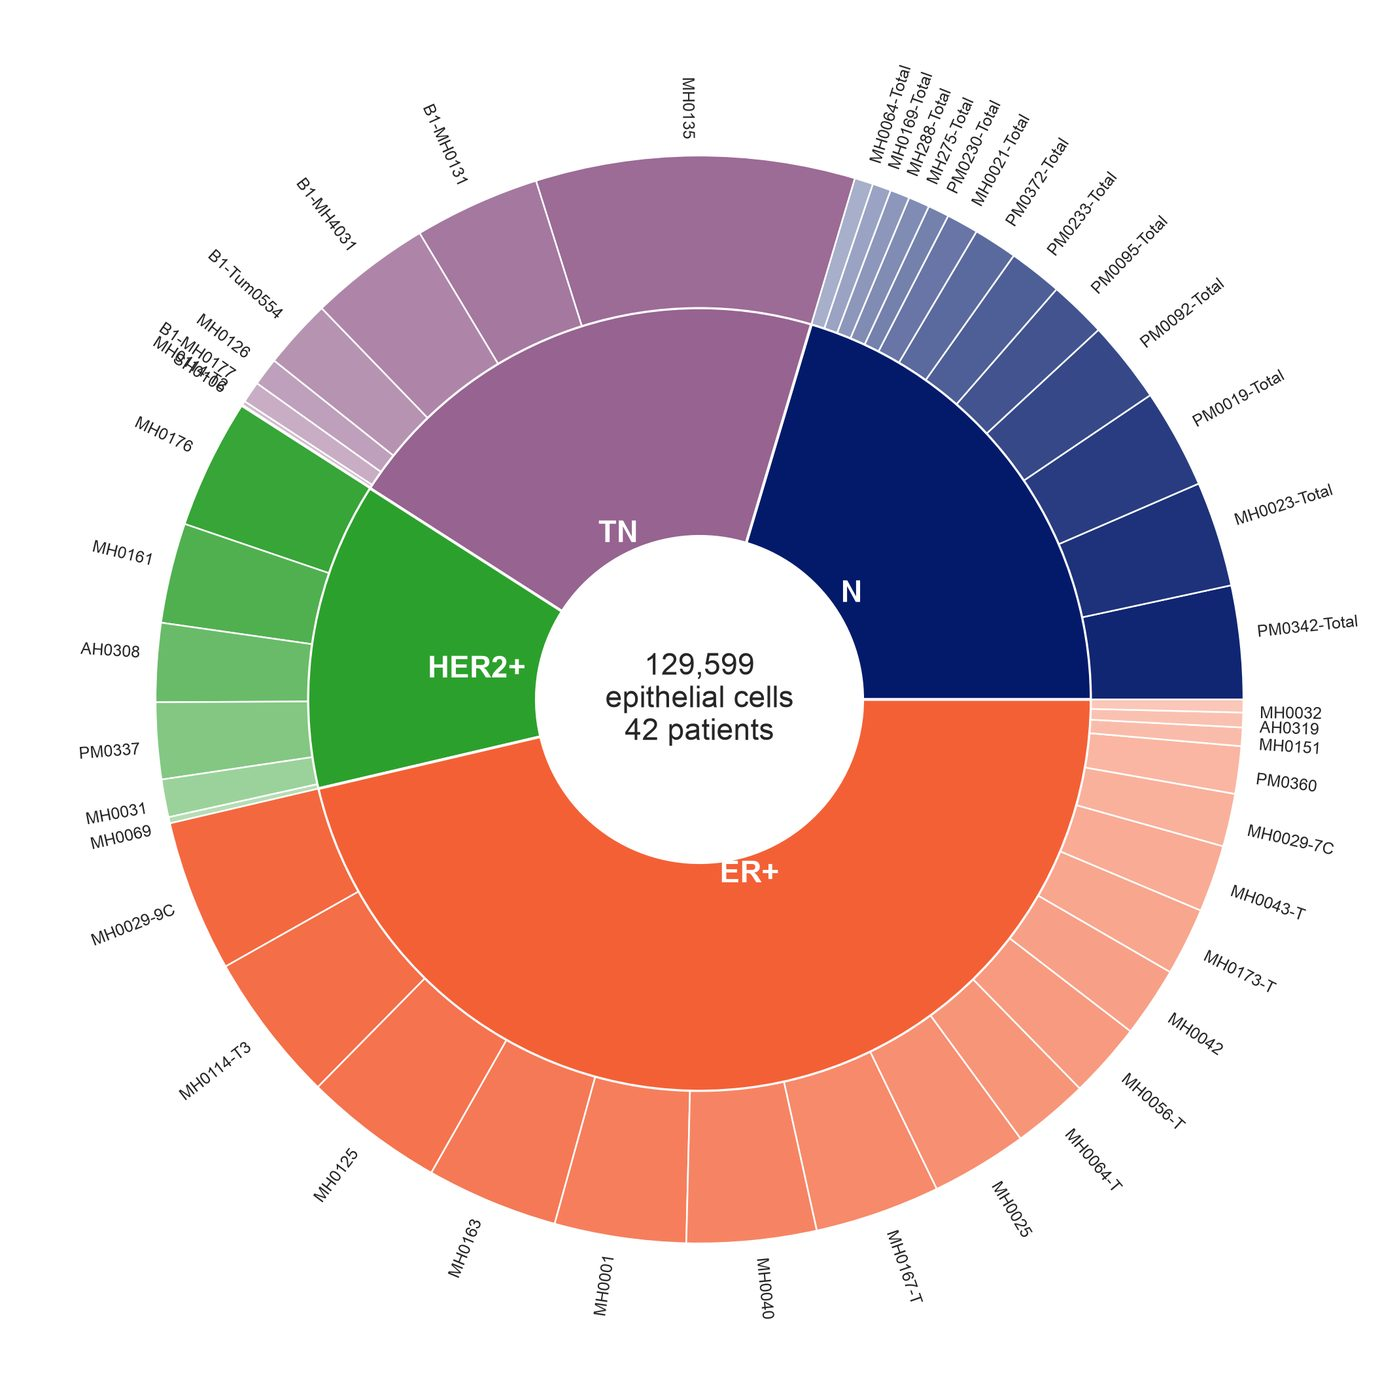

In [115]:
# Supplementary Figure 1g - which samples contribute the epithelial cohort. Inner ring is the clinical condition, outer ring the individual samples.
contrib = (epi.obs.groupby(["condition", "sample_short"], observed=True)
           .size().rename("cells").reset_index())

contrib["rank"] = contrib["condition"].map(condition_rank)
contrib = contrib.sort_values(["rank", "cells"], ascending=[True, False])

inner = contrib.groupby("condition", observed=True)["cells"].sum().reindex(
    [c for c in condition_order if c in set(contrib["condition"])])

inner_colors = [condition_palette.get(c, condition_palette.get(c.rstrip("+"), "lightgrey"))
                for c in inner.index]
outer_colors = []
for c, col in zip(inner.index, inner_colors):
    n = int((contrib["condition"] == c).sum())
    outer_colors += [to_rgba(col, alpha=a) for a in np.linspace(0.95, 0.35, n)]

fig, ax = plt.subplots(figsize=(9, 9))

ax.pie(inner.values, radius=0.72, colors=inner_colors,
       labels=inner.index, labeldistance=0.45,
       wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1),
       textprops=dict(fontsize=11, weight="bold", color="white"))

ax.pie(contrib["cells"].values, radius=1.0, colors=outer_colors,
       labels=contrib["sample_short"], labeldistance=1.03, rotatelabels=True,
       wedgeprops=dict(width=0.28, edgecolor="white", linewidth=0.6),
       textprops=dict(fontsize=6))

ax.set(aspect="equal")
ax.text(0, 0, f"{epi.n_obs:,}\nepithelial cells\n{epi.obs['patient'].nunique()} patients",
        ha="center", va="center", fontsize=11)

plt.savefig(fig_dir / "supp1g_epithelial_contribution.png", dpi=300, bbox_inches="tight")
plt.show()

contrib.to_csv(df_dir / "epithelial_contribution_per_sample.csv", index=False)

In [116]:
epi_mask = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
x = np.asarray(adata[:, "EPCAM"].layers["log1p"].todense()).ravel() > 0
print(f"EPCAM+ inside  epithelial : {100*x[epi_mask].mean():.1f}%")
print(f"EPCAM+ outside epithelial : {100*x[~epi_mask].mean():.1f}%")


EPCAM+ inside  epithelial : 48.1%
EPCAM+ outside epithelial : 1.8%


In [117]:
conn  = adata.obsp["connectivities"].tocsr()
codes = adata.obs["sample"].astype("category").cat.codes.to_numpy()
same  = (codes[conn.indices] == np.repeat(codes, np.diff(conn.indptr)))
adata.obs["frac_same_sample"] = np.add.reduceat(same, conn.indptr[:-1]) / np.maximum(np.diff(conn.indptr), 1)

p = adata.obs["sample"].value_counts(normalize=True).to_numpy()
print(f"expected if perfectly mixed: {(p**2).sum():.3f}\n")
print(adata.obs.groupby("cl_annotation")["frac_same_sample"].median().round(3).sort_values().to_string())


expected if perfectly mixed: 0.032

cl_annotation
T Cells                           0.255
Mast Cells                        0.272
Perivascular                      0.272
T/NK Cells                        0.293
Endothelial                       0.323
Macrophages                       0.327
Epithelial: Mature Luminal        0.353
Fibroblasts                       0.395
B Cells                           0.419
Endothelial: Lymphatic            0.433
Epithelial                        0.433
Epithelial: Luminal Progenitor    0.452
Epithelial: Cycling               0.460
Dendritic Cells                   0.531
Plasma Cells                      0.564
Epithelial: Basal                 0.595


In [118]:
import session_info

In [119]:
session_info.show()